# Séries temporais: previsão diária de doses aplicadas

**Projeto:** PI IV – Vacinação em Porto Alegre (PNI/2026)
**Tabela:** `pi4-vacinacao-poa.pni_gold.tb_series_temporais_doses_v3`

**Objetivo:** prever a quantidade diária de doses aplicadas em moradores de Porto Alegre, comparando modelos de séries temporais, como apoio ao acompanhamento da demanda de vacinação pela Vigilância Epidemiológica.

**Dados:** doses aplicadas em moradores de Porto Alegre (município de residência do paciente), de 01/01 a 25/09/2026, extraídas do Portal de Dados Abertos do SUS em 02/10/2026.

**Etapas:** preparação da série → análise exploratória → decomposição → divisão em treino e teste → modelos de referência → SARIMA → Prophet → comparação dos modelos → previsão futura.

Este notebook adapta o notebook original de séries temporais do grupo, elaborado pela Karen, para a base corrigida (v3).

In [1]:
import warnings, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4.5)

PROJECT_ID = "pi4-vacinacao-poa"
DATASET    = "pni_gold"
TABLE      = "tb_series_temporais_doses_v3"

COL_DATA   = "data_aplicacao"
COL_VACINA = "sg_imunobiologico"
COL_DOSES  = "total_doses_aplicadas"

TOP_N_VACINAS = 5
HORIZONTE     = 28
SAZONALIDADE  = 7

FIG_DIR = Path("figuras_series_temporais"); FIG_DIR.mkdir(parents=True, exist_ok=True)
def salvar(nome):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nome}.png", dpi=300, bbox_inches="tight", facecolor="white")

print("Configuração carregada.")

Configuração carregada.


In [2]:
from google.colab import auth
from google.cloud import bigquery

auth.authenticate_user()
client = bigquery.Client(project=PROJECT_ID)

schema = client.query(f'''
    SELECT column_name, data_type
    FROM `{PROJECT_ID}.{DATASET}.INFORMATION_SCHEMA.COLUMNS`
    WHERE table_name = '{TABLE}'
    ORDER BY ordinal_position
''').to_dataframe()
display(schema)

df_raw = client.query(f"SELECT * FROM `{PROJECT_ID}.{DATASET}.{TABLE}`").to_dataframe()
print(df_raw.shape)
df_raw.head(10)

,column_name,data_type
0,data_aplicacao,DATE
1,sg_imunobiologico,STRING
2,ds_tipo_dose,STRING
3,total_doses_aplicadas,INT64
4,pacientes_atendidos,INT64


(29179, 5)


,data_aplicacao,sg_imunobiologico,ds_tipo_dose,total_doses_aplicadas,pacientes_atendidos
0,2026-07-19,BCG,Dose,1,1
1,2026-09-19,BCG,Dose,1,1
2,2026-07-15,BCG,Dose,1,1
3,2026-06-01,BCG,Dose,1,1
4,2026-04-27,BCG,Dose,1,1
5,2026-01-08,BCG,Dose,1,1
6,2026-07-28,BCG,Dose,1,1
7,2026-08-16,BCG,Dose,1,1
8,2026-06-15,BCG,Dose,1,1
9,2026-03-01,BCG,Dose,1,1


In [3]:
df = df_raw.copy()
datas = pd.to_datetime(df[COL_DATA])

dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

display(datas.dt.day_name().value_counts().reindex(dias).rename("linhas"))
display(df.groupby(datas.dt.day_name())[COL_DOSES].sum().reindex(dias).rename("doses"))

,linhas
data_aplicacao,
Monday,4845
Tuesday,4800
Wednesday,4964
Thursday,4911
Friday,4950
Saturday,3432
Sunday,1277


,doses
data_aplicacao,
Monday,232619
Tuesday,206953
Wednesday,215918
Thursday,192357
Friday,198993
Saturday,97769
Sunday,12071


Os dados foram obtidos do BigQuery (projeto "pi4-vacinacao-poa", tabela "tb_series_temporais_doses_v3"). A base tem **29.179 registros e 5 colunas**: data da aplicação, vacina ("sg_imunobiologico"), tipo de dose ("ds_tipo_dose"), total de doses aplicadas e pacientes atendidos. A soma das doses é de 1.156.680, igual ao total de registros de vacinação de moradores de Porto Alegre na camada Silver, o que confirma que nenhuma dose se perdeu na agregação.

**Leitura inicial:**

* Cada registro é a combinação de **dia + vacina + tipo de dose**. Para a análise de série temporal, as doses serão somadas por dia.
* A distribuição por dia da semana mostra atividade concentrada **de segunda a sexta** (entre 192 mil e 233 mil doses por dia da semana no período), queda no **sábado** (cerca de 98 mil) e volume muito menor no **domingo** (cerca de 12 mil). Isso indica funcionamento reduzido nos fins de semana, o que deve aparecer como **sazonalidade semanal** na série temporal.

In [4]:
df[COL_DATA] = pd.to_datetime(df[COL_DATA], errors="coerce")

print("Nulos por coluna:\n", df.isna().sum(), "\n")
print("Datas inválidas:", df[COL_DATA].isna().sum())
print("Período:", df[COL_DATA].min().date(), "→", df[COL_DATA].max().date())
print("Imunobiológicos distintos:", df[COL_VACINA].nunique())
print("Doses negativas:", (df[COL_DOSES] < 0).sum())
dup = df.duplicated(subset=[COL_DATA, COL_VACINA]).sum()
print("Linhas repetidas (data × vacina):", dup)

dias_completos = pd.date_range(df[COL_DATA].min(), df[COL_DATA].max(), freq="D")
faltantes = dias_completos.difference(df[COL_DATA].dropna().unique())
print(f"Dias sem nenhum registro: {len(faltantes)}", list(faltantes.date[:10]))

ult = df.groupby(COL_DATA)[COL_DOSES].sum().sort_index().tail(14)
print("\nÚltimos 14 dias:\n", ult)

Nulos por coluna:
 data_aplicacao           0
sg_imunobiologico        0
ds_tipo_dose             0
total_doses_aplicadas    0
pacientes_atendidos      0
dtype: int64 

Datas inválidas: 0
Período: 2026-01-01 → 2026-09-26
Imunobiológicos distintos: 72
Doses negativas: 0
Linhas repetidas (data × vacina): 18359
Dias sem nenhum registro: 0 []

Últimos 14 dias:
 data_aplicacao
2026-09-13      83
2026-09-14    3751
2026-09-15    3372
2026-09-16    3339
2026-09-17    3157
2026-09-18    3324
2026-09-19     255
2026-09-20      69
2026-09-21    1773
2026-09-22    3046
2026-09-23    2907
2026-09-24    2958
2026-09-25    3654
2026-09-26       1
Name: total_doses_aplicadas, dtype: Int64


In [5]:
df = df[df[COL_DATA] <= "2026-09-25"]
print("Período:", df[COL_DATA].min().date(), "→", df[COL_DATA].max().date())
print("Dias:", df[COL_DATA].nunique())

Período: 2026-01-01 → 2026-09-25
Dias: 268


**Verificação da qualidade dos dados**

A base não apresenta valores nulos, datas inválidas ou doses negativas, e não há nenhum dia sem registro no período. Foram identificados **72 imunobiológicos** distintos.

As 18.359 linhas com a mesma combinação de data e vacina não são erros: correspondem a tipos de dose diferentes da mesma vacina no mesmo dia e serão somadas na agregação diária.

A base vai de 01/01/2026 a 26/09/2026, mas o último dia tem apenas 1 dose registrada, contra 255 no sábado anterior. Esse valor indica que a extração dos dados ocorreu durante o dia 26/09, que foi removido. A série analisada vai de **01/01/2026 a 25/09/2026 (268 dias)**. O dia 21/09 também ficou abaixo do habitual para uma segunda-feira (1.773 doses), mas foi mantido, porque os dias seguintes voltaram ao nível normal e não há evidência de registro incompleto.

Os últimos 14 dias mostram uma **sazonalidade semanal** forte: nos dias úteis são aplicadas, em geral, entre 2.900 e 3.750 doses, no sábado cerca de 250 e no domingo menos de 100. Esse padrão de período 7 deve ser considerado nos modelos (por exemplo, com sazonalidade semanal no SARIMA ou no Prophet).

In [6]:
serie_total = df.groupby(COL_DATA)[COL_DOSES].sum().asfreq("D", fill_value=0)

top = df.groupby(COL_VACINA)[COL_DOSES].sum().sort_values(ascending=False)
vacinas_top = top.head(TOP_N_VACINAS).index.tolist()
print("Participação dos 15 imunobiológicos mais aplicados (%):")
display((top / top.sum() * 100).head(15).round(2))

pivot = (df[df[COL_VACINA].isin(vacinas_top)]
         .pivot_table(index=COL_DATA, columns=COL_VACINA, values=COL_DOSES, aggfunc="sum")
         .asfreq("D").fillna(0))
series = {"TOTAL": serie_total, **{v: pivot[v] for v in vacinas_top}}
print("Séries montadas:", list(series.keys()))

Participação dos 15 imunobiológicos mais aplicados (%):


,total_doses_aplicadas
sg_imunobiologico,
INF3,40.51
COV-19 PFIZER-COMIRN,8.0
INF4,7.5
dT,4.9
HB,4.85
VIP,3.12
DNG,2.42
MenACWY,2.35
VFA,2.3


Séries montadas: ['TOTAL', 'INF3', 'COV-19 PFIZER-COMIRN', 'INF4', 'dT', 'HB']


**Participação das vacinas no total de doses**

A distribuição das doses é bastante concentrada. A vacina contra influenza trivalente (INF3) responde sozinha por **40,5%** do total e, somada à quadrivalente (INF4, 7,5%), a **influenza chega a cerca de 48% das doses** aplicadas no período. Em seguida vêm COVID-19 Pfizer (8,0%), dT (4,9%) e hepatite B (4,9%). As 15 vacinas mais aplicadas somam cerca de 87% do total.

A concentração da INF3 sugere aplicação em um período curto, típica de **campanha de vacinação**. Se for isso, a série diária total deve mostrar um pico no período da campanha. Esse ponto será avaliado na análise exploratória e considerado na modelagem.

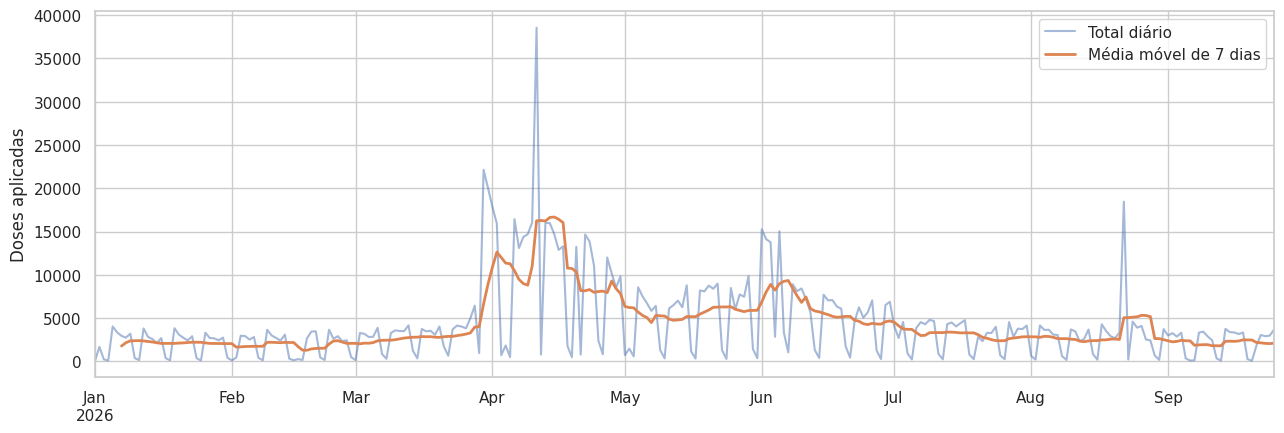

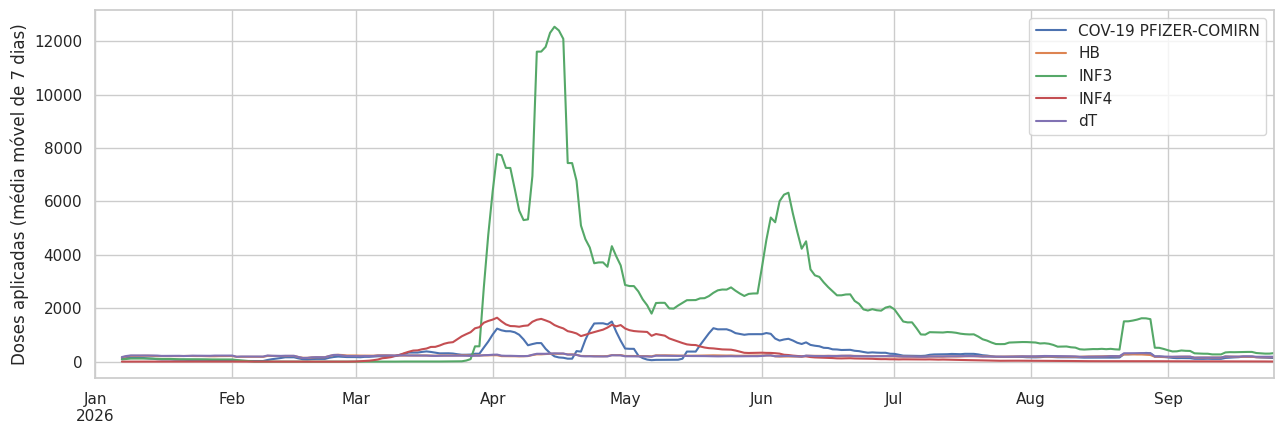

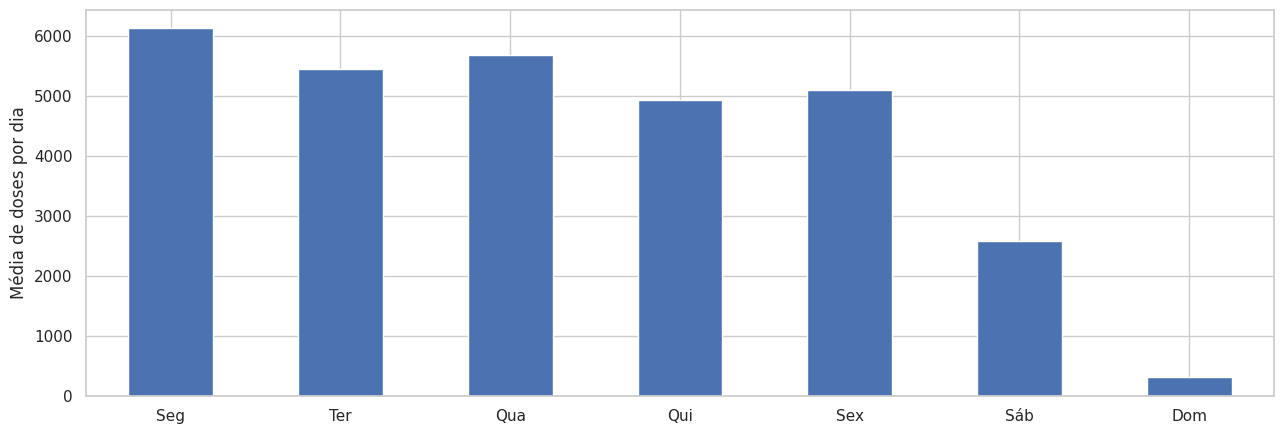

In [7]:
fig, ax = plt.subplots()
serie_total.plot(ax=ax, alpha=.5, label="Total diário")
serie_total.rolling(7).mean().plot(ax=ax, lw=2, label="Média móvel de 7 dias")
ax.set_xlabel(""); ax.set_ylabel("Doses aplicadas"); ax.legend()
salvar("01_total_diario"); plt.show()

fig, ax = plt.subplots()
pivot.rolling(7).mean().plot(ax=ax)
ax.set_xlabel(""); ax.set_ylabel("Doses aplicadas (média móvel de 7 dias)"); ax.legend(title="")
salvar("02_top_vacinas"); plt.show()

nomes = {0: "Seg", 1: "Ter", 2: "Qua", 3: "Qui", 4: "Sex", 5: "Sáb", 6: "Dom"}
dow = serie_total.groupby(serie_total.index.dayofweek).mean().reindex(range(7))
dow.index = [nomes[i] for i in dow.index]
fig, ax = plt.subplots()
dow.plot(kind="bar", ax=ax)
ax.set_xlabel(""); ax.set_ylabel("Média de doses por dia"); plt.xticks(rotation=0)
salvar("03_dia_semana"); plt.show()

**Análise exploratória**

A série diária mostra três eventos que se destacam do volume habitual de dias úteis (entre 2.000 e 4.500 doses):

* **Campanha de vacinação contra a gripe (a partir do fim de março):** o volume sobe de forma acentuada, com o maior pico da série em **11/04**, Dia D de vacinação contra a gripe (cerca de 38 mil doses de moradores de Porto Alegre). O gráfico por imunobiológico mostra que o pico vem quase todo da INF3. A INF4 começa a subir antes, em março, e perde força depois de abril.
* **Ampliação da vacinação contra a gripe para toda a população (1º/06):** uma segunda onda da INF3, com dias de cerca de 15 mil doses, que coincide com a liberação da vacina para todas as pessoas com mais de seis meses de idade.
* **Dia D da Campanha Nacional de Multivacinação (22/08):** um pico isolado de cerca de 18,5 mil doses, com uma pequena alta da INF3 na mesma semana.

A covid apresenta ondas menores em abril e entre maio e o início de junho. Hepatite B (HB) e dT ficam estáveis e baixas durante todo o período, sem efeito de campanha.

A média por dia da semana confirma a sazonalidade semanal: volume alto de segunda a sexta (entre cerca de 4.900 e 6.100 doses), queda no sábado e volume mínimo no domingo (cerca de 300 doses). A média do sábado (cerca de 2.600) está inflada pelos dois Dias D, que ocorreram em sábados. Em um sábado comum, o volume fica em torno de 250 doses.

**Implicações para a modelagem:**

* usar modelos com componente sazonal semanal (SARIMA com s = 7 e Prophet com sazonalidade semanal);
* os eventos de campanha geram picos que não se repetem no período de teste e podem distorcer o nível estimado pelos modelos;
* o Dia D de 22/08 fica na última semana do treino, o que afeta diretamente os modelos que usam a semana mais recente como referência;
* como a série tem menos de um ano, as campanhas aparecem uma única vez, e o modelo não consegue aprender que elas se repetem todo ano. Isso deve ser citado como limitação.

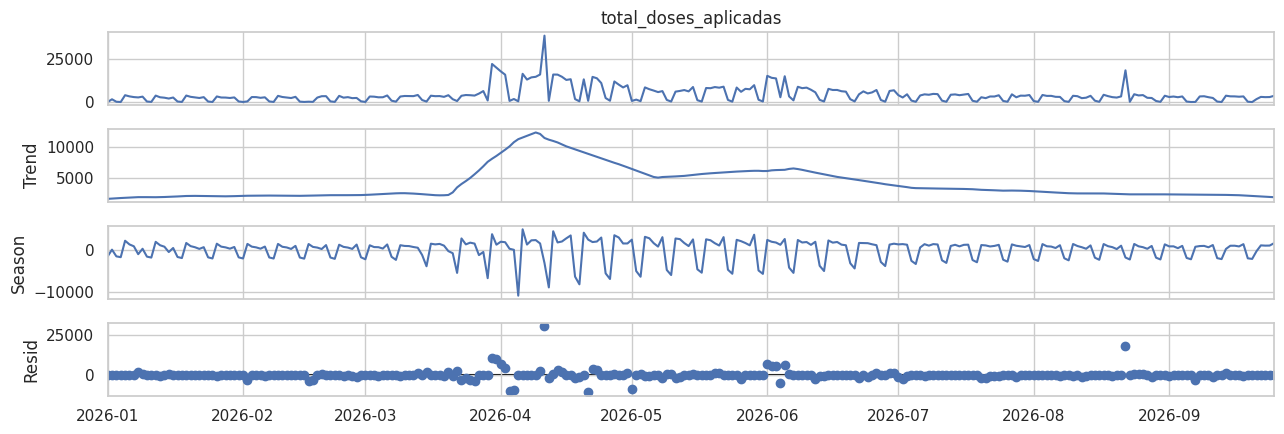

ADF p-valor = 0.2789 → não estacionária (diferenciar)


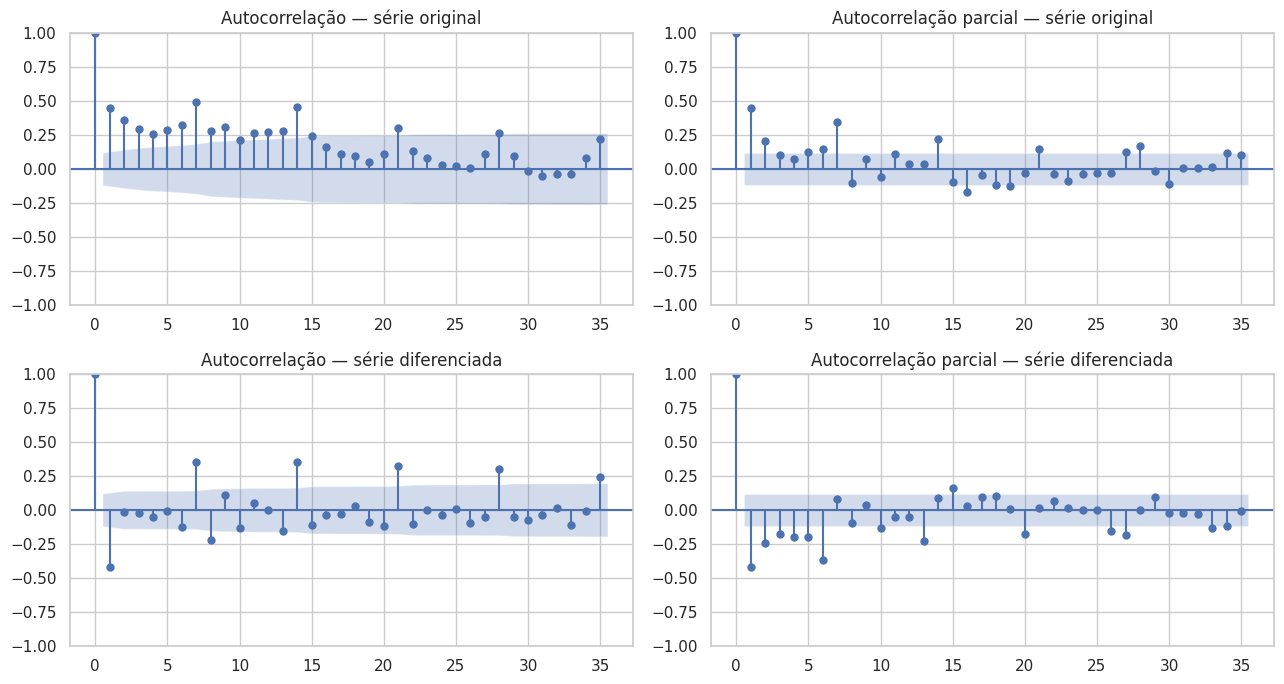

In [8]:
stl = STL(serie_total, period=SAZONALIDADE, robust=True).fit()
stl.plot(); salvar("04_decomposicao_stl"); plt.show()

adf = adfuller(serie_total)
print(f"ADF p-valor = {adf[1]:.4f} →", "estacionária" if adf[1] < .05 else "não estacionária (diferenciar)")

fig, axs = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(serie_total, lags=35, ax=axs[0, 0], title="Autocorrelação — série original")
plot_pacf(serie_total, lags=35, ax=axs[0, 1], title="Autocorrelação parcial — série original")
plot_acf(serie_total.diff().dropna(), lags=35, ax=axs[1, 0], title="Autocorrelação — série diferenciada")
plot_pacf(serie_total.diff().dropna(), lags=35, ax=axs[1, 1], title="Autocorrelação parcial — série diferenciada")
salvar("05_acf_pacf"); plt.show()

**Decomposição, estacionariedade e autocorrelação**

A decomposição STL separa a série em tendência, sazonalidade e resíduo. A **tendência** sobe a partir do fim de março, atinge o máximo em meados de abril (cerca de 12 mil doses diárias), tem uma segunda alta menor no início de junho e depois cai lentamente até cerca de 2,5 mil doses em setembro. A **sazonalidade semanal** aparece durante todo o período, mas com amplitude proporcional ao nível da série: a queda do fim de semana chega a cerca de 10 mil doses durante a campanha de abril e fica em torno de 2 mil nos meses sem campanha. Isso indica uma sazonalidade de natureza **multiplicativa**. Os dois Dias D (11/04 e 22/08) aparecem como valores extremos isolados no **resíduo**, o que confirma que são eventos pontuais, não explicados pela tendência nem pela sazonalidade.

O teste de Dickey-Fuller aumentado (ADF) resultou em p-valor de 0,279, acima de 0,05. A série **não é estacionária** e precisa ser diferenciada.

Na série original, a função de autocorrelação (ACF) decai lentamente e tem picos nas defasagens 7, 14, 21 e 28, sinal de tendência combinada com sazonalidade semanal. Na série diferenciada, a ACF mostra uma autocorrelação negativa forte na defasagem 1 (cerca de −0,42), padrão característico de um termo de média móvel de ordem 1. Os picos nas defasagens 7, 14, 21 e 28 continuam significativos (entre 0,30 e 0,35) e decaem lentamente, o que indica que a diferenciação simples não remove a sazonalidade e que é necessária também uma **diferenciação sazonal de período 7**.

Essas características correspondem à especificação **SARIMA(0,1,1)(0,1,1)₇**, avaliada adiante junto com modelos de ordem escolhida por busca e com o Prophet.

In [9]:
def split(s, h=HORIZONTE): return s.iloc[:-h], s.iloc[-h:]
tr, te = split(serie_total)
print(f"Treino: {tr.index.min().date()} → {tr.index.max().date()} ({len(tr)} dias)")
print(f"Teste : {te.index.min().date()} → {te.index.max().date()} ({len(te)} dias)")

Treino: 2026-01-01 → 2026-08-28 (240 dias)
Teste : 2026-08-29 → 2026-09-25 (28 dias)


**Divisão em treino e teste**

A série foi dividida respeitando a ordem temporal, sem embaralhamento:

* **Treino:** 01/01/2026 a 28/08/2026 (240 dias, cerca de 90%);
* **Teste:** 29/08/2026 a 25/09/2026 (28 dias, cerca de 10%).

O conjunto de teste tem exatamente **4 semanas completas**, de sábado a sexta-feira, então cada dia da semana aparece 4 vezes e a avaliação fica equilibrada em relação à sazonalidade semanal. O horizonte de 28 dias corresponde a uma previsão de cerca de um mês.

Os picos da campanha de influenza (abril e junho) ficam inteiramente no treino, e o teste corresponde a um período de volume mais baixo e estável. O Dia D da Multivacinação (22/08) fica na **última semana do treino**, e os primeiros dias do teste (29/08 a 01/09) ainda pertencem à Campanha de Multivacinação, encerrada em 1º de setembro. Os efeitos desses eventos sobre os modelos são avaliados na modelagem.

In [10]:
def metricas(y, yhat):
    y, yhat = np.asarray(y, float), np.clip(np.asarray(yhat, float), 0, None)
    smape = np.mean(2*np.abs(yhat-y) / np.where((np.abs(y)+np.abs(yhat))==0, 1, np.abs(y)+np.abs(yhat))) * 100
    return {"MAE": mean_absolute_error(y, yhat),
            "RMSE": np.sqrt(mean_squared_error(y, yhat)),
            "sMAPE_%": smape}

def baseline_naive(tr, h):
    return np.repeat(tr.iloc[-1], h)

def baseline_sazonal(tr, h, s=SAZONALIDADE):
    return np.resize(tr.iloc[-s:].values, h)

def baseline_media_dow(tr, h):
    ult = tr.iloc[-28:]; m = ult.groupby(ult.index.dayofweek).mean()
    idx = pd.date_range(tr.index[-1] + pd.Timedelta(days=1), periods=h)
    return m.reindex(idx.dayofweek).values

print("Funções definidas.")

Funções definidas.


**Métricas de avaliação e modelos de referência**

**Métricas.** Os modelos são comparados no conjunto de teste (28 dias) com:
- **MAE** (erro absoluto médio): quantas doses, em média, a previsão erra por dia. É a métrica de leitura mais direta;
- **RMSE** (raiz do erro quadrático médio): pesa mais os erros grandes e mostra se o modelo erra muito em alguns dias. É o critério usado para escolher o melhor modelo de cada série;
- **sMAPE** (erro percentual absoluto médio simétrico): mede o erro em termos relativos, entre 0% e 200%. Foi escolhido no lugar do MAPE porque não cresce sem limite em dias de volume baixo, como os domingos.

Previsões negativas são ajustadas para zero antes do cálculo, já que não existem doses negativas.

**Modelos de referência.** Servem de parâmetro mínimo de desempenho:
- **Ingênuo:** repete o último valor do treino (28/08, uma sexta-feira) em todos os dias. Ignora a sazonalidade semanal;
- **Sazonal ingênuo:** repete a última semana do treino, reproduzindo o padrão semanal;
- **Média por dia da semana:** usa a média de cada dia da semana nas últimas 4 semanas do treino.

Um modelo só é considerado útil se tiver erro menor que o do melhor modelo de referência.

Modelo da busca: SARIMA(0, 1, 2)x(1, 1, 1, 7)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.7337      0.031    -23.534      0.000      -0.795      -0.673
ma.L2         -0.0498      0.044     -1.143      0.253      -0.135       0.036
ar.S.L7       -0.0370      0.055     -0.678      0.498      -0.144       0.070
ma.S.L7       -0.8520      0.058    -14.813      0.000      -0.965      -0.739
sigma2      1.493e+07    2.6e-09   5.74e+15      0.000    1.49e+07    1.49e+07


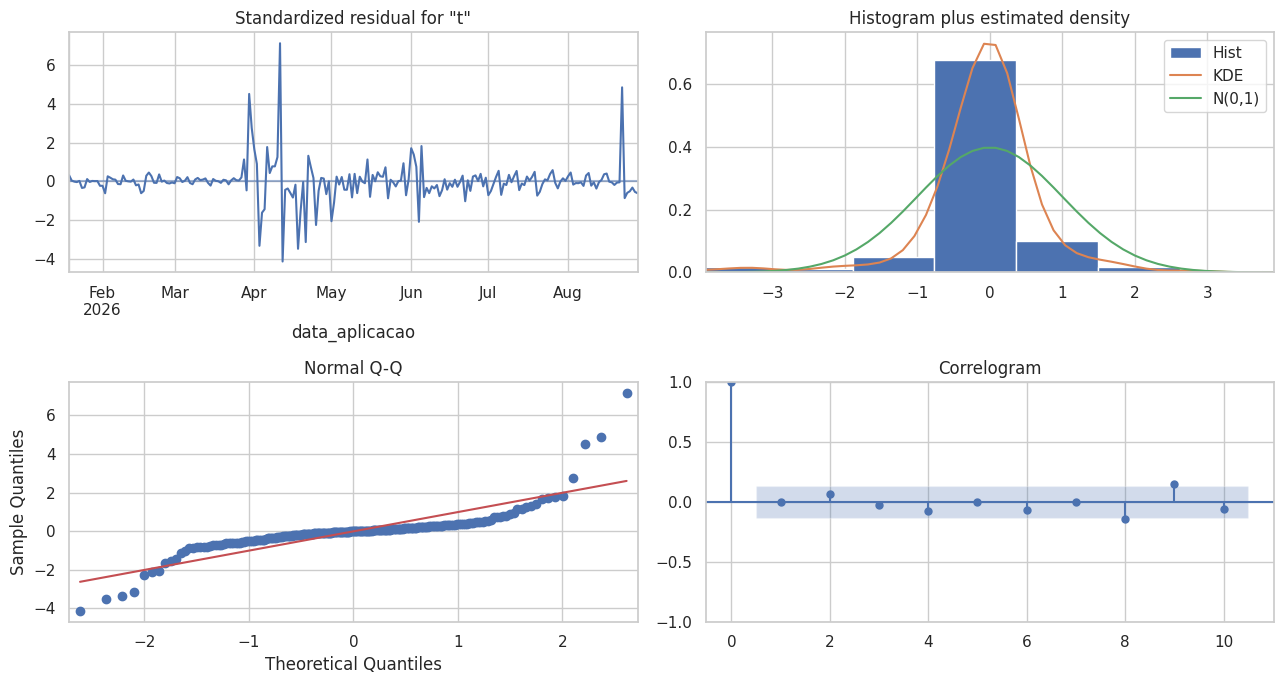

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.7694      0.037    -20.785      0.000      -0.842      -0.697
ma.S.L7       -0.8550      0.059    -14.453      0.000      -0.971      -0.739
sigma2      2.711e+07   6.89e-10   3.94e+16      0.000    2.71e+07    2.71e+07
AIC  SARIMA(0, 1, 2)x(1, 1, 1, 7): 4308.9 | SARIMA(0,1,1)x(0,1,1,7): 4357.1
Busca : {'MAE': 1082.2528643143016, 'RMSE': np.float64(1527.015195029418), 'sMAPE_%': np.float64(72.61779492272122)}
Fixo  : {'MAE': 1078.8009743847538, 'RMSE': np.float64(1547.3785001820545), 'sMAPE_%': np.float64(72.43399550839968)}
                  real    prev  smape
data_aplicacao                       
Friday          3177.5  3834.8   19.7
Monday          2343.5  4595.3   79.7
Saturday         401.8  3124.3  155.4
Sunday           104.8     0.0  200.0
Thursday        2961.2  3286.6   10.4
Tuesday         3181.5  3995

In [11]:
def ajustar_sarima(tr, s=SAZONALIDADE):
    melhor = (np.inf, None, None, None)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for p, d, q in itertools.product(range(3), range(2), range(3)):
            for P, D, Q in itertools.product(range(2), range(2), range(2)):
                try:
                    m = SARIMAX(tr, order=(p,d,q), seasonal_order=(P,D,Q,s),
                                enforce_stationarity=False,
                                enforce_invertibility=False).fit(disp=False)
                    if m.aic < melhor[0]:
                        melhor = (m.aic, (p,d,q), (P,D,Q,s), m)
                except Exception:
                    pass
    if melhor[3] is None:
        raise RuntimeError("Nenhum SARIMA convergiu.")
    return melhor[3], melhor[1], melhor[2]

def prev_sarima(tr, h):
    m, o, so = ajustar_sarima(tr)
    return np.clip(m.forecast(h).values, 0, None), f"SARIMA{o}x{so}", m

yhat, nome, m_total = prev_sarima(tr, HORIZONTE)
print("Modelo da busca:", nome)
print(m_total.summary().tables[1])

fig = m_total.plot_diagnostics(figsize=(13, 7)); fig.tight_layout()
salvar("06_sarima_diagnostico"); plt.show()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m_simples = SARIMAX(tr, order=(0,1,1), seasonal_order=(0,1,1,SAZONALIDADE),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
yhat_simples = np.clip(m_simples.forecast(HORIZONTE).values, 0, None)
print(m_simples.summary().tables[1])

print(f"AIC  {nome}: {m_total.aic:.1f} | SARIMA(0,1,1)x(0,1,1,7): {m_simples.aic:.1f}")
print("Busca :", metricas(te, yhat))
print("Fixo  :", metricas(te, yhat_simples))

yhat_sarima, nome_sarima, m_sarima = yhat_simples, "SARIMA(0,1,1)x(0,1,1,7)", m_simples

res = pd.DataFrame({"real": te.values, "prev": yhat_sarima}, index=te.index)
res["smape"] = 200*abs(res.prev-res.real)/(res.real+res.prev).replace(0, 1)
print(res.groupby(res.index.day_name())[["real","prev","smape"]].mean().round(1))

**Modelo SARIMA**

Os resultados desta seção correspondem à primeira rodada de modelagem, com os dados originais, antes da correção do Dia D da Multivacinação (22/08), descrita na seção de comparação dos modelos.

A busca em grade pelo menor AIC resultou no SARIMA(0,1,2)(1,1,1)₇. Os termos MA(2) e AR sazonal não foram significativos (p = 0,25 e p = 0,50), e o modelo sem eles corresponde ao SARIMA(0,1,1)(0,1,1)₇, a especificação indicada pela análise de autocorrelação.

| Modelo | AIC | MAE | RMSE | sMAPE |
| --- | --- | --- | --- | --- |
| SARIMA(0,1,2)(1,1,1)₇ (busca) | 4.308,9 | 1.082 | 1.527 | 72,6% |
| SARIMA(0,1,1)(0,1,1)₇ (fixo) | 4.357,1 | 1.079 | 1.079 | 72,4% |

O modelo da busca ajusta melhor o treino (AIC menor), mas os dois têm desempenho praticamente igual no teste. O modelo fixo foi mantido por ter menos parâmetros e ser justificado pela análise de autocorrelação.

**Erros por dia da semana.** Nos dias úteis, o erro percentual fica entre 10% e 23%, com exceção da segunda-feira (80%), cujas observações no teste ficaram abaixo do habitual. Nos fins de semana, o modelo falha. No sábado, previu cerca de 3.100 doses contra cerca de 400 reais, porque o Dia D da Multivacinação (22/08), com cerca de 18,5 mil doses, ocorreu no último sábado do treino e elevou a estimativa para esse dia da semana. No domingo, o modelo previu valores negativos, ajustados para zero, já que a sazonalidade aditiva trata a queda do fim de semana como um valor fixo, enquanto a decomposição mostrou que essa queda é proporcional ao nível da série.

**Diagnóstico dos resíduos:** o correlograma não mostra autocorrelação significativa, o que indica que a estrutura da série foi capturada. O gráfico Q-Q mostra caudas pesadas, concentradas nos picos de campanha e nos dois Dias D, então os intervalos de previsão devem ser interpretados com cautela.

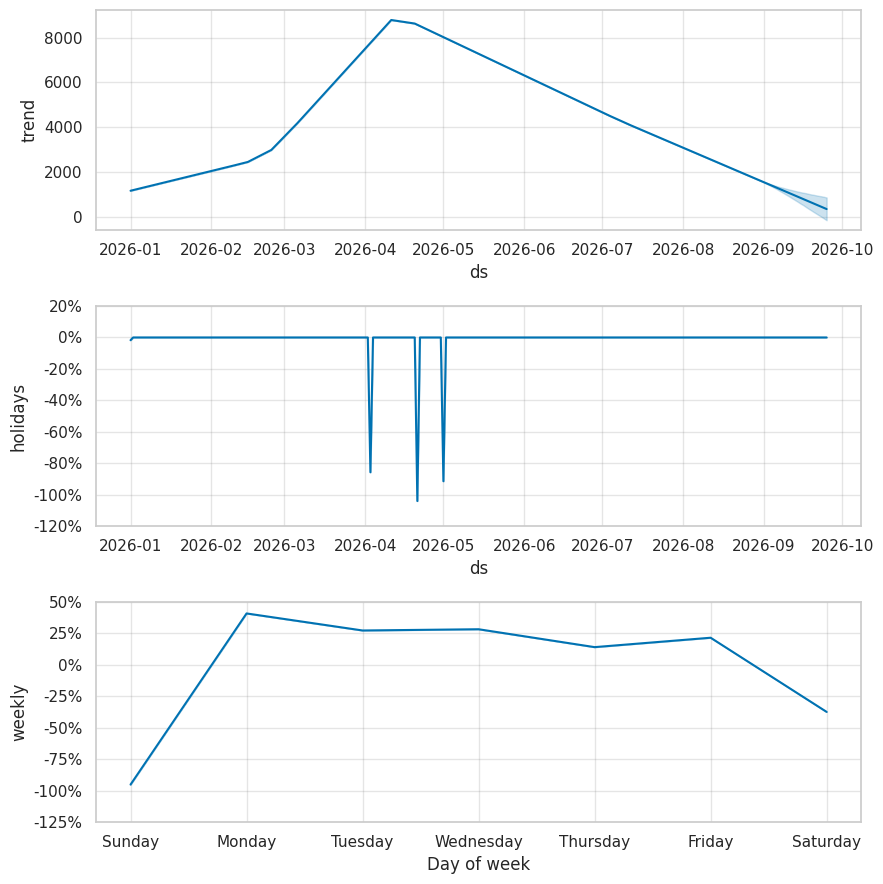

Prophet: {'MAE': 1412.4608094208347, 'RMSE': np.float64(1688.529097793569), 'sMAPE_%': np.float64(85.20186680449508)}
SARIMA : {'MAE': 1078.8009743847538, 'RMSE': np.float64(1547.3785001820545), 'sMAPE_%': np.float64(72.43399550839968)}
                  real    prev  smape
data_aplicacao                       
Friday          3177.5  1069.0  100.3
Monday          2343.5  1518.5   99.6
Saturday         401.8   737.7   59.3
Sunday           104.8    55.8   60.3
Thursday        2961.2  1060.0   97.8
Tuesday         3181.5  1309.3   86.8
Wednesday       3233.0  1255.8   92.3


In [12]:
from prophet import Prophet
import holidays as hol
import logging
logging.getLogger("cmdstanpy").disabled = True

anos = range(tr.index.min().year, tr.index.max().year + 2)
feriados_br = pd.DataFrame(
    [(pd.Timestamp(d), nome) for d, nome in hol.Brazil(years=anos).items()],
    columns=["ds", "holiday"]
).drop_duplicates(subset="ds").reset_index(drop=True)

def prev_prophet(tr, h, retornar_modelo=False):
    d = tr.astype(float).rename_axis("ds").reset_index(name="y")
    m = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                seasonality_mode="multiplicative", holidays=feriados_br,
                changepoint_range=0.95, changepoint_prior_scale=0.1)
    m.fit(d)
    fc = m.predict(m.make_future_dataframe(periods=h, include_history=False))
    return (fc, m) if retornar_modelo else np.clip(fc["yhat"].values, 0, None)

fc, m_p = prev_prophet(tr, HORIZONTE, retornar_modelo=True)
yhat_prophet = np.clip(fc["yhat"].values, 0, None)
m_p.plot_components(m_p.predict(m_p.make_future_dataframe(HORIZONTE)))
salvar("07_prophet_componentes"); plt.show()

print("Prophet:", metricas(te, yhat_prophet))
print("SARIMA :", metricas(te, yhat_sarima))

res_p = pd.DataFrame({"real": te.values, "prev": yhat_prophet}, index=te.index)
res_p["smape"] = 200*abs(res_p.prev-res_p.real)/(res_p.real+res_p.prev).replace(0, 1)
print(res_p.groupby(res_p.index.day_name())[["real","prev","smape"]].mean().round(1))

**Modelo Prophet**

Assim como na seção anterior, os resultados abaixo correspondem à primeira rodada de modelagem, antes da correção do Dia D da Multivacinação (22/08).

Foi ajustado um modelo Prophet com sazonalidade semanal multiplicativa, sem sazonalidade anual (a série tem menos de um ano), com feriados nacionais brasileiros e com pontos de mudança de tendência permitidos até 95% do treino (changepoint_range = 0,95).

| Modelo | MAE | RMSE | sMAPE |
| --- | --- | --- | --- |
| SARIMA(0,1,1)(0,1,1)₇ | 1.079 | 1.547 | 72,4% |
| Prophet | 1.412 | 1.689 | 85,2% |

O Prophet teve desempenho inferior ao SARIMA em todas as métricas. O gráfico de componentes mostra a causa: a **tendência** estimada sobe até meados de abril e depois cai de forma praticamente linear até o fim do treino, sem capturar a segunda onda de junho nem a estabilização do volume a partir de julho. Projetada para o teste, essa queda leva a previsões de cerca de 1.000 a 1.500 doses nos dias úteis, contra 2.300 a 3.200 observadas, com erro percentual acima de 87% em todos os dias úteis.

Nos fins de semana, o Prophet teve desempenho melhor que o SARIMA. A sazonalidade multiplicativa representa a queda do fim de semana como proporção do nível (cerca de −95% no domingo e −38% no sábado), e o padrão semanal, estimado com todo o histórico, foi pouco afetado pelo Dia D de 22/08: a previsão para o sábado foi de cerca de 740 doses, contra cerca de 3.100 do SARIMA (valor real: cerca de 400).

O componente de **feriados** mostra quedas de 85% a 104% na Sexta-feira Santa, em Tiradentes e no Dia do Trabalho. O efeito acima de 100% faz o modelo prever valores negativos nesses dias.

In [13]:
def prev_sarima_simples(tr, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = SARIMAX(tr, order=(0,1,1), seasonal_order=(0,1,1,SAZONALIDADE),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return np.clip(m.forecast(h).values, 0, None)

resultados, previsoes = [], {}
for nome_serie, s in series.items():
    tr_s, te_s = split(s)
    prevs = {"Naive": baseline_naive(tr_s, HORIZONTE),
             "Sazonal ingênuo (7d)": baseline_sazonal(tr_s, HORIZONTE),
             "Média dia-semana 4sem": baseline_media_dow(tr_s, HORIZONTE)}
    sar, nome_sar, _ = prev_sarima(tr_s, HORIZONTE)
    prevs["SARIMA (busca)"] = sar
    prevs["SARIMA(0,1,1)(0,1,1)7"] = prev_sarima_simples(tr_s, HORIZONTE)
    prevs["Prophet"] = prev_prophet(tr_s, HORIZONTE)
    previsoes[nome_serie] = (tr_s, te_s, prevs)

    espec = {"SARIMA (busca)": nome_sar,
             "SARIMA(0,1,1)(0,1,1)7": "SARIMA(0,1,1)x(0,1,1,7)"}
    for modelo, yh in prevs.items():
        resultados.append({"serie": nome_serie, "modelo": modelo,
                           "especificacao": espec.get(modelo, ""),
                           **metricas(te_s, yh)})
    print("ok:", nome_serie, "| busca:", nome_sar)

res_comp = pd.DataFrame(resultados)
display(res_comp.pivot(index="serie", columns="modelo", values="RMSE").round(1))
melhor = res_comp.loc[res_comp.groupby("serie")["RMSE"].idxmin(),
                      ["serie", "modelo", "MAE", "RMSE", "sMAPE_%"]]
display(melhor.round(2))
res_comp.to_csv("resultados_series_temporais.csv", index=False)

ok: TOTAL | busca: SARIMA(0, 1, 2)x(1, 1, 1, 7)
ok: INF3 | busca: SARIMA(1, 1, 2)x(0, 1, 1, 7)
ok: COV-19 PFIZER-COMIRN | busca: SARIMA(1, 1, 2)x(0, 1, 1, 7)
ok: INF4 | busca: SARIMA(2, 1, 2)x(0, 1, 1, 7)
ok: dT | busca: SARIMA(0, 1, 2)x(0, 1, 1, 7)
ok: HB | busca: SARIMA(0, 1, 2)x(0, 1, 1, 7)


modelo,Média dia-semana 4sem,Naive,Prophet,SARIMA (busca),"SARIMA(0,1,1)(0,1,1)7",Sazonal ingênuo (7d)
serie,,,,,,
COV-19 PFIZER-COMIRN,113.5,103.4,172.6,78.1,73.9,340.4
HB,76.6,107.4,52.6,61.8,63.3,200.3
INF3,779.0,237.0,417.1,616.9,579.9,2875.0
INF4,12.0,10.4,12.9,6.8,6.1,7.8
TOTAL,2019.1,1421.6,1688.5,1527.0,1547.4,6919.7
dT,102.8,120.0,57.5,77.5,81.3,307.0


,serie,modelo,MAE,RMSE,sMAPE_%
16,COV-19 PFIZER-COMIRN,"SARIMA(0,1,1)(0,1,1)7",57.85,73.93,60.06
35,HB,Prophet,32.91,52.61,32.55
6,INF3,Naive,209.46,237.01,80.65
22,INF4,"SARIMA(0,1,1)(0,1,1)7",4.89,6.05,69.72
0,TOTAL,Naive,1228.32,1421.57,71.86
29,dT,Prophet,30.08,57.52,26.97


In [14]:
DIA_D = pd.Timestamp("2026-08-22")
SABADOS_REF = pd.to_datetime(["2026-07-25", "2026-08-01", "2026-08-08", "2026-08-15"])

series_corr, conferencia = {}, []
for nome_serie, s in series.items():
    s_corr = s.copy()
    valor_novo = int(round(float(s.loc[SABADOS_REF].median())))
    conferencia.append({"serie": nome_serie,
                        "22/08 original": s.loc[DIA_D],
                        **{d.strftime("%d/%m"): s.loc[d] for d in SABADOS_REF},
                        "22/08 corrigido": valor_novo})
    s_corr.loc[DIA_D] = valor_novo
    series_corr[nome_serie] = s_corr

display(pd.DataFrame(conferencia).set_index("serie"))

,22/08 original,25/07,01/08,08/08,15/08,22/08 corrigido
serie,,,,,,
TOTAL,18444,688,618,600,841,653
INF3,7589,157,86,126,197,142
COV-19 PFIZER-COMIRN,866,44,19,12,31,25
INF4,21,53,34,30,21,32
dT,812,45,44,42,42,43
HB,525,54,46,40,45,46


In [15]:
series_corr["INF4"] = series["INF4"].copy()

resultados_corr, previsoes_corr = [], {}
for nome_serie, s in series_corr.items():
    tr_s, te_s = split(s)
    prevs = {"Naive": baseline_naive(tr_s, HORIZONTE),
             "Sazonal ingênuo (7d)": baseline_sazonal(tr_s, HORIZONTE),
             "Média dia-semana 4sem": baseline_media_dow(tr_s, HORIZONTE)}
    sar, nome_sar, _ = prev_sarima(tr_s, HORIZONTE)
    prevs["SARIMA (busca)"] = sar
    prevs["SARIMA(0,1,1)(0,1,1)7"] = prev_sarima_simples(tr_s, HORIZONTE)
    prevs["Prophet"] = prev_prophet(tr_s, HORIZONTE)
    previsoes_corr[nome_serie] = (tr_s, te_s, prevs)

    espec = {"SARIMA (busca)": nome_sar,
             "SARIMA(0,1,1)(0,1,1)7": "SARIMA(0,1,1)x(0,1,1,7)"}
    for modelo, yh in prevs.items():
        resultados_corr.append({"serie": nome_serie, "modelo": modelo,
                                "especificacao": espec.get(modelo, ""),
                                **metricas(te_s, yh)})
    print("ok:", nome_serie, "| busca:", nome_sar)

res_comp_corr = pd.DataFrame(resultados_corr)
display(res_comp_corr.pivot(index="serie", columns="modelo", values="RMSE").round(1))
melhor_corr = res_comp_corr.loc[res_comp_corr.groupby("serie")["RMSE"].idxmin(),
                                ["serie", "modelo", "MAE", "RMSE", "sMAPE_%"]]
display(melhor_corr.round(2))
res_comp_corr.to_csv("resultados_series_temporais_corrigido.csv", index=False)

ok: TOTAL | busca: SARIMA(0, 1, 2)x(1, 1, 1, 7)
ok: INF3 | busca: SARIMA(1, 1, 2)x(0, 1, 1, 7)
ok: COV-19 PFIZER-COMIRN | busca: SARIMA(1, 1, 2)x(0, 1, 1, 7)
ok: INF4 | busca: SARIMA(2, 1, 2)x(0, 1, 1, 7)
ok: dT | busca: SARIMA(0, 1, 2)x(0, 1, 1, 7)
ok: HB | busca: SARIMA(0, 1, 2)x(0, 1, 1, 7)


modelo,Média dia-semana 4sem,Naive,Prophet,SARIMA (busca),"SARIMA(0,1,1)(0,1,1)7",Sazonal ingênuo (7d)
serie,,,,,,
COV-19 PFIZER-COMIRN,75.0,103.4,172.4,76.4,72.6,101.4
HB,57.3,107.4,52.2,53.5,53.6,70.6
INF3,231.3,237.0,417.3,298.8,237.2,318.7
INF4,12.0,10.4,12.9,6.8,6.1,7.8
TOTAL,948.6,1421.6,1994.4,872.0,873.2,1178.3
dT,65.1,120.0,55.8,60.1,60.2,74.0


,serie,modelo,MAE,RMSE,sMAPE_%
16,COV-19 PFIZER-COMIRN,"SARIMA(0,1,1)(0,1,1)7",51.50,72.59,58.52
35,HB,Prophet,33.44,52.16,30.89
8,INF3,Média dia-semana 4sem,163.39,231.33,69.99
22,INF4,"SARIMA(0,1,1)(0,1,1)7",4.89,6.05,69.72
3,TOTAL,SARIMA (busca),566.24,872.05,76.94
29,dT,Prophet,30.03,55.78,22.48


**Comparação dos modelos: segunda rodada, após a correção do Dia D**

Foram comparados seis modelos em cada série, com horizonte de teste de 28 dias: três modelos de referência (ingênuo, sazonal ingênuo de 7 dias e média por dia da semana das últimas 4 semanas), um SARIMA com ordem escolhida por busca em grade, um SARIMA de especificação fixa (0,1,1)(0,1,1)₇ e o Prophet.

**Efeito do Dia D da Multivacinação.** Na primeira rodada, com os dados originais, o Dia D de 22/08, último sábado do treino, distorceu os resultados. O sazonal ingênuo, que repete a última semana, teve RMSE de 6.920 no TOTAL. O SARIMA previu cerca de 3.100 doses para os sábados do teste, contra cerca de 400 reais. Na série TOTAL e na INF3, o melhor modelo foi o ingênuo, que não representa a sazonalidade semanal. Por isso, o valor de 22/08 foi substituído pela mediana dos quatro sábados anteriores (25/07 a 15/08) nas séries em que ele superava todos esses sábados: TOTAL, INF3, COV-19, dT e HB. Na INF4, o valor do Dia D estava dentro da faixa habitual e foi mantido. O Dia D de 11/04 não foi alterado, porque ocorreu durante a campanha de influenza, quando o nível da série estava elevado, e está distante do fim do treino.

Melhor modelo por série na segunda rodada (RMSE no conjunto de teste)

| **Série** | **Melhor modelo** | **MAE** | **RMSE** | **sMAPE (%)** |
|---|---|---:|---:|---:|
| TOTAL | SARIMA (busca) | 566,2 | 872,1 | 76,9 |
| INF3 | Média por dia da semana (4 semanas) | 163,4 | 231,3 | 70,0 |
| COV-19 Pfizer | SARIMA(0,1,1)(0,1,1)₇ | 51,5 | 72,6 | 58,5 |
| INF4 | SARIMA(0,1,1)(0,1,1)₇ | 4,9 | 6,1 | 69,7 |
| HB | Prophet | 33,4 | 52,2 | 30,9 |
| dT | Prophet | 30,0 | 55,8 | 22,5 |

Nenhum modelo foi o melhor em todas as séries, e várias diferenças são pequenas. No TOTAL, o SARIMA da busca e o SARIMA fixo ficaram praticamente empatados (872,1 e 873,2). Na INF3, a média por dia da semana, o ingênuo e o SARIMA fixo ficaram a menos de 3% um do outro (231,3, 237,0 e 237,2). Na HB, o Prophet e os dois SARIMA também ficaram a menos de 3%.

O SARIMA(0,1,1)(0,1,1)₇ ficou em primeiro lugar ou a menos de 3% do primeiro em cinco das seis séries, com exceção da dT. A busca em grade acrescentou termos que não melhoraram a previsão em nenhuma série e piorou o resultado na INF3 (298,8 contra 237,2). Com séries curtas e com eventos de campanha, o modelo mais simples generalizou melhor, o que reforça o princípio da parcimônia.

O Prophet foi o melhor nas séries de rotina (HB e dT), que têm volume estável e não são afetadas por campanhas, mas teve o pior desempenho no TOTAL, na INF3 e na COV-19. Nessas séries, a tendência estimada projetou a queda posterior às campanhas para o período de teste e subestimou o volume observado.

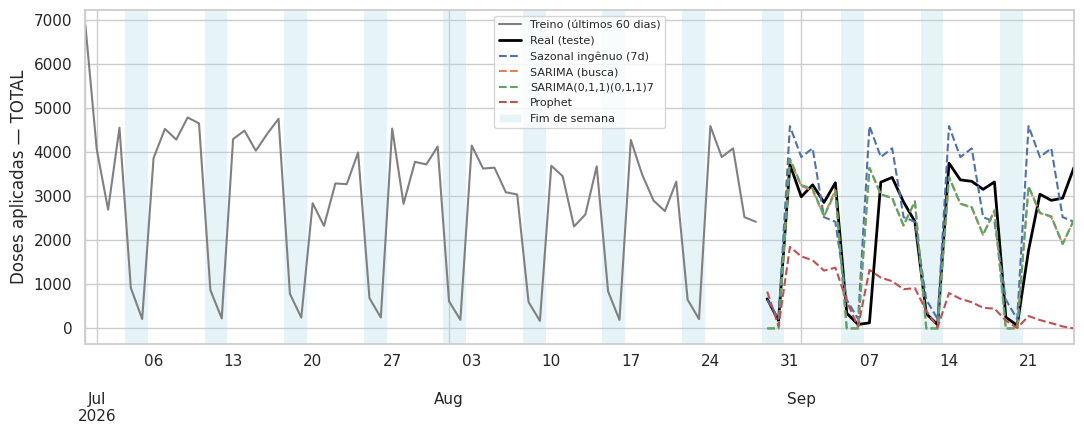

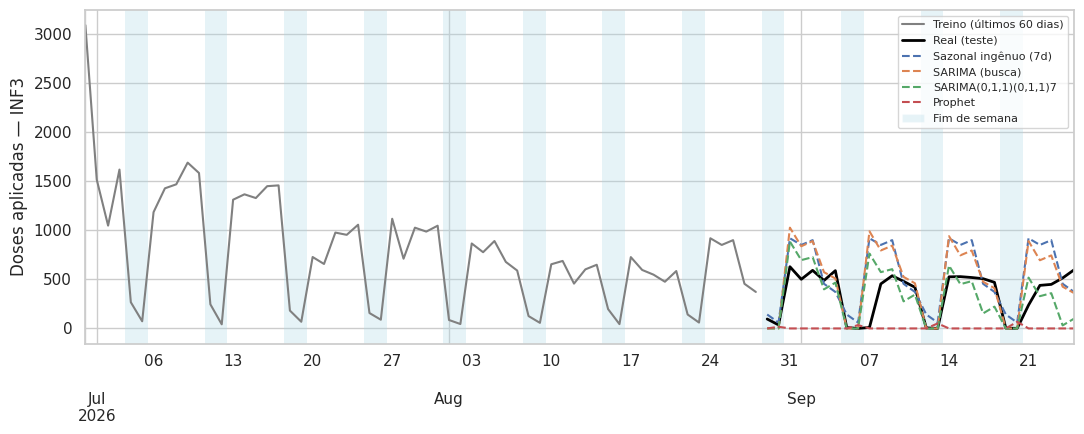

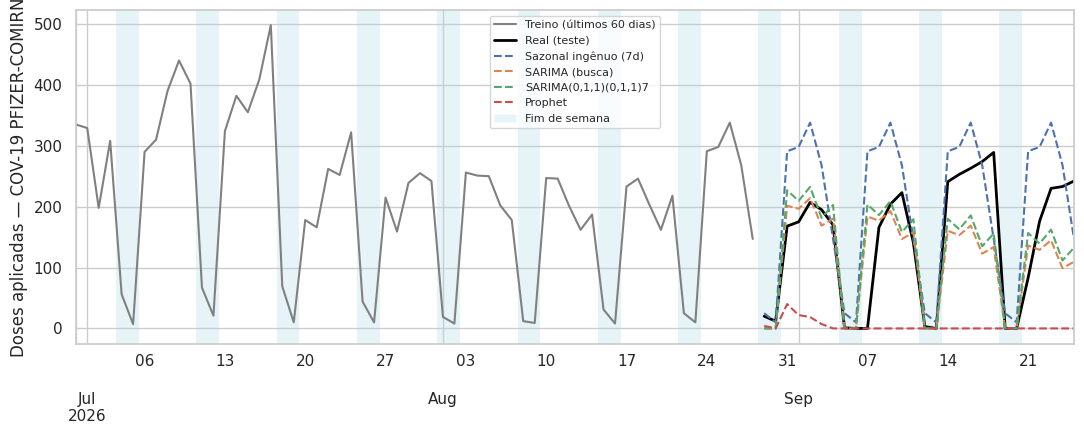

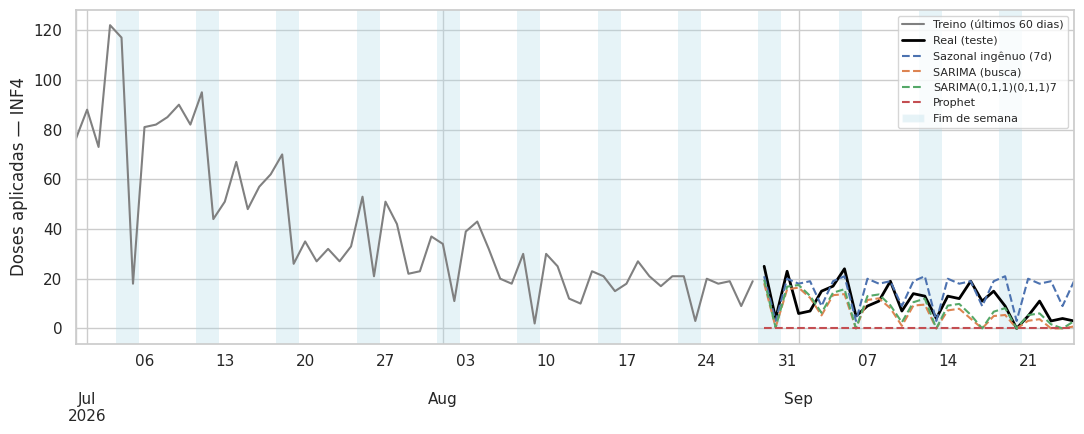

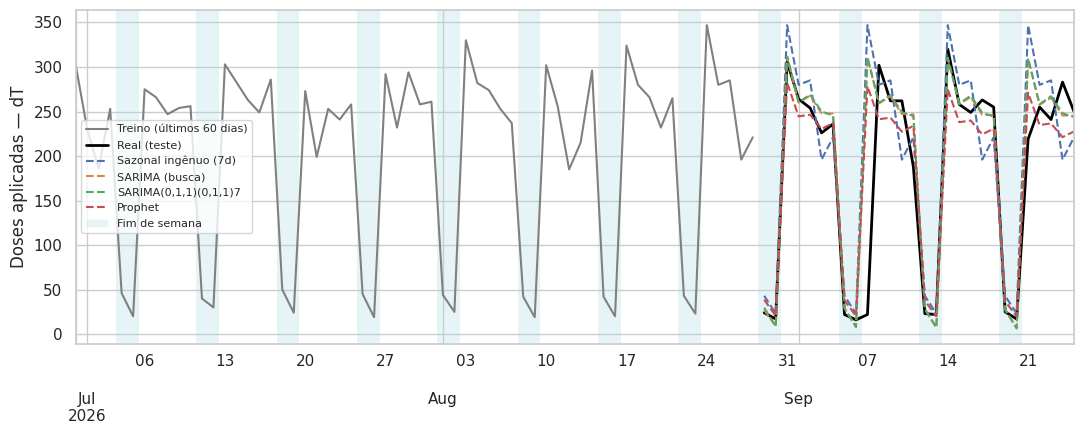

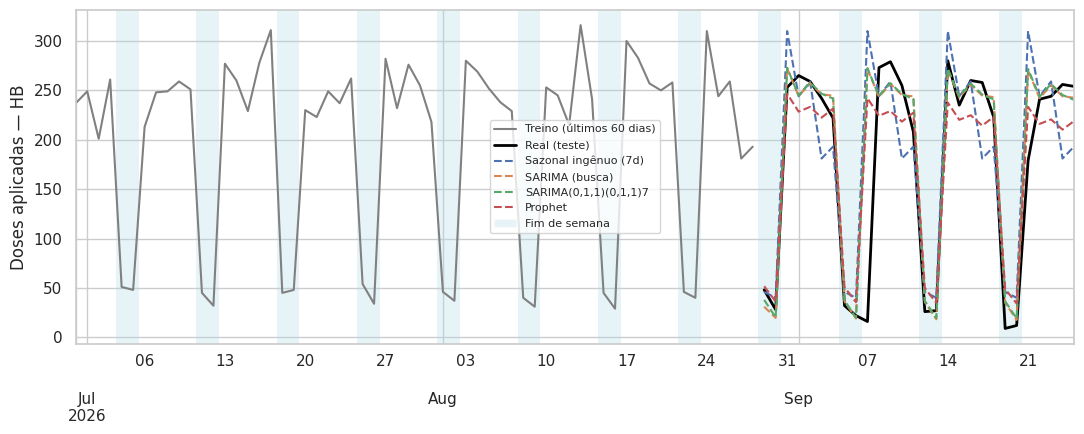

In [16]:
from matplotlib.patches import Patch

modelos_plot = ["Sazonal ingênuo (7d)", "SARIMA (busca)", "SARIMA(0,1,1)(0,1,1)7", "Prophet"]

for nome_serie, (tr_s, te_s, prevs) in previsoes_corr.items():
    fig, ax = plt.subplots(figsize=(11, 4.5))
    tr_s.iloc[-60:].plot(ax=ax, color="gray", label="Treino (últimos 60 dias)")
    te_s.plot(ax=ax, color="black", lw=2, label="Real (teste)")
    for mod in modelos_plot:
        ax.plot(te_s.index, np.clip(prevs[mod], 0, None), "--", label=mod)

    idx = tr_s.index[-60:].append(te_s.index)
    for d in idx[idx.dayofweek == 5]:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(days=1, hours=12),
                   color="lightblue", alpha=0.3, lw=0)

    handles, labels = ax.get_legend_handles_labels()
    handles.append(Patch(facecolor="lightblue", alpha=0.3)); labels.append("Fim de semana")
    ax.legend(handles, labels, fontsize=8)
    ax.set_xlabel(""); ax.set_ylabel(f"Doses aplicadas — {nome_serie}")
    salvar(f"08_prev_{str(nome_serie)[:30].replace(' ','_').replace('/','-')}")
    plt.show(); plt.close(fig)

**Previsão e valores reais no período de teste**

Os gráficos confirmam os resultados da segunda rodada e mostram dois grupos de séries com comportamentos distintos.

Nas **séries de rotina (HB e dT)**, o padrão semanal é estável (cerca de 250 doses por dia útil e de 20 a 50 nos fins de semana), e os dois SARIMA e o Prophet acompanham os valores observados de perto. O Prophet fica ligeiramente abaixo do real nos dias úteis, mas erra menos nos fins de semana, o que explica seu RMSE menor.

Nas **séries afetadas por campanhas (INF3, COV-19 e INF4)**, o Prophet projeta para o teste a queda observada após as campanhas: a tendência estimada fica negativa, e a previsão é igual a zero em praticamente todo o período. Nessas séries, o Prophet não produz previsões úteis. Os SARIMA acompanham o padrão semanal, mas erram o nível: na INF3, o modelo da busca superestima os dias úteis (cerca de 900 a 1.000 doses, contra cerca de 500 reais), e o modelo fixo termina o período abaixo do real. Na COV-19, os dois SARIMA acertam as duas primeiras semanas e subestimam as duas últimas, quando o volume real subiu para cerca de 250 a 290 doses. Na INF4, o volume é muito baixo (de 0 a 25 doses por dia), e os SARIMA acompanham bem a queda, com erro médio de cerca de 5 doses por dia. O sMAPE próximo de 70% nessa série resulta do volume baixo, e não de um desempenho ruim.

No **TOTAL**, os dois SARIMA acompanham o real nas quatro semanas, enquanto o Prophet decresce continuamente e o sazonal ingênuo superestima os dias úteis, por repetir a última semana do treino, ainda dentro da Campanha de Multivacinação.

Em todas as séries, o maior erro individual ocorre em **07/09**, feriado da Independência, que caiu em uma segunda-feira. O SARIMA não incorpora feriados e previu volume de dia útil para essa data. O Prophet inclui feriados nacionais, mas, nas séries de campanha, a tendência já estava tão baixa que o efeito do feriado é pouco visível.

In [17]:
def prev_sarima_log(s, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = SARIMAX(np.log1p(s.astype(float)), order=(0,1,1),
                    seasonal_order=(0,1,1,SAZONALIDADE),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return np.expm1(np.asarray(m.forecast(h)))

funcoes = {
    "Naive":                 lambda s, h: baseline_naive(s, h),
    "Sazonal ingênuo (7d)":  lambda s, h: baseline_sazonal(s, h),
    "Média dia-semana 4sem": lambda s, h: baseline_media_dow(s, h),
    "SARIMA (busca)":        lambda s, h: prev_sarima(s, h)[0],
    "SARIMA(0,1,1)(0,1,1)7": lambda s, h: prev_sarima_simples(s, h),
    "SARIMA log":            prev_sarima_log,
    "Prophet":               lambda s, h: prev_prophet(s, h),
}
substituir = {}

futuro, resumo = {}, []
for _, r in melhor_corr.iterrows():
    mod = substituir.get(r.serie, r.modelo)
    s = series_corr[r.serie]
    bruto = np.asarray(funcoes[mod](s, HORIZONTE), dtype=float)

    n_neg = int((bruto < 0).sum())
    if n_neg:
        print(f"⚠ {r.serie}: {n_neg} valor(es) negativo(s) previsto(s) com {mod}")

    futuro[r.serie] = np.clip(bruto, 0, None).round()
    ult_sem = s.iloc[-7:].sum()
    sem1, sem2 = futuro[r.serie][:7].sum(), futuro[r.serie][7:14].sum()
    resumo.append({"serie": r.serie, "melhor no teste": r.modelo, "modelo usado": mod,
                   "última semana": int(ult_sem), "prev. semana 1": int(sem1),
                   "prev. semana 2": int(sem2),
                   "var. sem1 vs últ. (%)": round(100 * (sem1 / ult_sem - 1), 1)})

display(pd.DataFrame(resumo).set_index("serie"))

idx = pd.date_range(serie_total.index[-1] + pd.Timedelta(days=1), periods=HORIZONTE)
df_futuro = pd.DataFrame(futuro, index=idx); df_futuro.index.name = "data"
display(df_futuro.head(14))
df_futuro.to_csv("previsao_proximas_semanas.csv")

,melhor no teste,modelo usado,última semana,prev. semana 1,prev. semana 2,var. sem1 vs últ. (%)
serie,,,,,,
COV-19 PFIZER-COMIRN,"SARIMA(0,1,1)(0,1,1)7","SARIMA(0,1,1)(0,1,1)7",964,1058,1015,9.8
HB,Prophet,Prophet,1195,1253,1240,4.9
INF3,Média dia-semana 4sem,Média dia-semana 4sem,2241,2409,2409,7.5
INF4,"SARIMA(0,1,1)(0,1,1)7","SARIMA(0,1,1)(0,1,1)7",35,7,0,-80.0
TOTAL,SARIMA (busca),SARIMA (busca),14662,15094,14453,2.9
dT,Prophet,Prophet,1290,1282,1269,-0.6


,COV-19 PFIZER-COMIRN,HB,INF3,INF4,TOTAL,dT
data,,,,,,
2026-09-26,0.0,50.0,28.0,4.0,0.0,37.0
2026-09-27,0.0,35.0,9.0,0.0,0.0,20.0
2026-09-28,174.0,246.0,351.0,0.0,3108.0,277.0
2026-09-29,208.0,230.0,480.0,2.0,3144.0,243.0
2026-09-30,237.0,235.0,524.0,1.0,3119.0,243.0
2026-10-01,220.0,225.0,498.0,0.0,2656.0,229.0
2026-10-02,219.0,232.0,519.0,0.0,3067.0,233.0
2026-10-03,0.0,49.0,28.0,0.0,0.0,36.0
2026-10-04,0.0,35.0,9.0,0.0,0.0,20.0


In [18]:
comp_log = []
for nome_serie, s in series_corr.items():
    tr_s, te_s = split(s)
    yhat_log = prev_sarima_log(tr_s, HORIZONTE)
    m = metricas(te_s, yhat_log)
    melhor_rmse = melhor_corr.set_index("serie").loc[nome_serie, "RMSE"]
    melhor_mod = melhor_corr.set_index("serie").loc[nome_serie, "modelo"]
    comp_log.append({"serie": nome_serie, "melhor modelo": melhor_mod,
                     "RMSE melhor": round(melhor_rmse, 1),
                     "RMSE SARIMA log": round(m["RMSE"], 1),
                     "MAE SARIMA log": round(m["MAE"], 1),
                     "sMAPE SARIMA log (%)": round(m["sMAPE_%"], 1)})

display(pd.DataFrame(comp_log).set_index("serie"))

,melhor modelo,RMSE melhor,RMSE SARIMA log,MAE SARIMA log,sMAPE SARIMA log (%)
serie,,,,,
TOTAL,SARIMA (busca),872.0,791.3,415.1,32.8
INF3,Média dia-semana 4sem,231.3,151.8,104.8,64.5
COV-19 PFIZER-COMIRN,"SARIMA(0,1,1)(0,1,1)7",72.6,65.0,44.3,66.9
INF4,"SARIMA(0,1,1)(0,1,1)7",6.1,4.9,3.9,43.5
dT,Prophet,55.8,62.1,29.1,23.1
HB,Prophet,52.2,51.3,27.0,29.0


In [19]:
linhas_log = []
for nome_serie, s in series_corr.items():
    tr_s, te_s, prevs = previsoes_corr[nome_serie]
    yhat_log = prev_sarima_log(tr_s, HORIZONTE)
    prevs["SARIMA log"] = yhat_log
    linhas_log.append({"serie": nome_serie, "modelo": "SARIMA log",
                       "especificacao": "SARIMA(0,1,1)x(0,1,1,7) em log",
                       **metricas(te_s, yhat_log)})

res_comp_corr = pd.concat([res_comp_corr[res_comp_corr["modelo"] != "SARIMA log"],
                           pd.DataFrame(linhas_log)], ignore_index=True)

display(res_comp_corr.pivot(index="serie", columns="modelo", values="RMSE").round(1))
melhor_corr = res_comp_corr.loc[res_comp_corr.groupby("serie")["RMSE"].idxmin(),
                                ["serie", "modelo", "MAE", "RMSE", "sMAPE_%"]]
display(melhor_corr.round(2))
res_comp_corr.to_csv("resultados_series_temporais_corrigido.csv", index=False)

modelo,Média dia-semana 4sem,Naive,Prophet,SARIMA (busca),SARIMA log,"SARIMA(0,1,1)(0,1,1)7",Sazonal ingênuo (7d)
serie,,,,,,,
COV-19 PFIZER-COMIRN,75.0,103.4,172.4,76.4,65.0,72.6,101.4
HB,57.3,107.4,52.2,53.5,51.3,53.6,70.6
INF3,231.3,237.0,417.3,298.8,151.8,237.2,318.7
INF4,12.0,10.4,12.9,6.8,4.9,6.1,7.8
TOTAL,948.6,1421.6,1994.4,872.0,791.3,873.2,1178.3
dT,65.1,120.0,55.8,60.1,62.1,60.2,74.0


,serie,modelo,MAE,RMSE,sMAPE_%
38,COV-19 PFIZER-COMIRN,SARIMA log,44.34,65.03,66.94
41,HB,SARIMA log,26.96,51.27,28.99
37,INF3,SARIMA log,104.84,151.81,64.50
39,INF4,SARIMA log,3.93,4.92,43.54
36,TOTAL,SARIMA log,415.06,791.32,32.83
29,dT,Prophet,30.03,55.78,22.48


In [20]:
substituir = {}

futuro, resumo = {}, []
for _, r in melhor_corr.iterrows():
    mod = substituir.get(r.serie, r.modelo)
    s = series_corr[r.serie]
    bruto = np.asarray(funcoes[mod](s, HORIZONTE), dtype=float)

    n_neg = int((bruto < 0).sum())
    if n_neg:
        print(f"⚠ {r.serie}: {n_neg} valor(es) negativo(s) previsto(s) com {mod}")

    futuro[r.serie] = np.clip(bruto, 0, None).round()
    ult_sem = s.iloc[-7:].sum()
    sem1, sem2 = futuro[r.serie][:7].sum(), futuro[r.serie][7:14].sum()
    resumo.append({"serie": r.serie, "melhor no teste": r.modelo, "modelo usado": mod,
                   "última semana": int(ult_sem), "prev. semana 1": int(sem1),
                   "prev. semana 2": int(sem2),
                   "var. sem1 vs últ. (%)": round(100 * (sem1 / ult_sem - 1), 1)})

display(pd.DataFrame(resumo).set_index("serie"))

idx = pd.date_range(serie_total.index[-1] + pd.Timedelta(days=1), periods=HORIZONTE)
df_futuro = pd.DataFrame(futuro, index=idx); df_futuro.index.name = "data"
display(df_futuro.head(14))
df_futuro.to_csv("previsao_proximas_semanas.csv")

⚠ INF4: 4 valor(es) negativo(s) previsto(s) com SARIMA log


,melhor no teste,modelo usado,última semana,prev. semana 1,prev. semana 2,var. sem1 vs últ. (%)
serie,,,,,,
COV-19 PFIZER-COMIRN,SARIMA log,SARIMA log,964,708,663,-26.6
HB,SARIMA log,SARIMA log,1195,1036,1012,-13.3
INF3,SARIMA log,SARIMA log,2241,2272,2252,1.4
INF4,SARIMA log,SARIMA log,35,16,10,-54.3
TOTAL,SARIMA log,SARIMA log,14662,13933,14010,-5.0
dT,Prophet,Prophet,1290,1282,1269,-0.6


,COV-19 PFIZER-COMIRN,HB,INF3,INF4,TOTAL,dT
data,,,,,,
2026-09-26,6.0,31.0,10.0,4.0,560.0,37.0
2026-09-27,2.0,25.0,2.0,0.0,151.0,20.0
2026-09-28,80.0,169.0,233.0,3.0,2631.0,277.0
2026-09-29,147.0,206.0,493.0,3.0,2559.0,243.0
2026-09-30,169.0,212.0,514.0,2.0,2880.0,243.0
2026-10-01,157.0,200.0,501.0,2.0,2571.0,229.0
2026-10-02,147.0,193.0,519.0,2.0,2581.0,233.0
2026-10-03,6.0,30.0,10.0,3.0,563.0,36.0
2026-10-04,2.0,24.0,2.0,0.0,152.0,20.0


In [21]:
def prev_sarima_log_corr(s, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = SARIMAX(np.log1p(s.astype(float)), order=(0,1,1),
                    seasonal_order=(0,1,1,SAZONALIDADE),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    s2 = float(m.params["sigma2"])
    return np.expm1(np.asarray(m.forecast(h)) + s2 / 2)

comp_vies = []
for nome_serie, s in series_corr.items():
    tr_s, te_s, prevs = previsoes_corr[nome_serie]
    yhat_c = prev_sarima_log_corr(tr_s, HORIZONTE)
    m_sem = metricas(te_s, prevs["SARIMA log"])
    m_com = metricas(te_s, yhat_c)
    fator = np.nanmean((yhat_c + 1) / (np.asarray(prevs["SARIMA log"]) + 1))
    comp_vies.append({"serie": nome_serie,
                      "fator de correção": round(fator, 3),
                      "RMSE log": round(m_sem["RMSE"], 1), "RMSE log corrigido": round(m_com["RMSE"], 1),
                      "MAE log": round(m_sem["MAE"], 1), "MAE log corrigido": round(m_com["MAE"], 1)})

display(pd.DataFrame(comp_vies).set_index("serie"))

,fator de correção,RMSE log,RMSE log corrigido,MAE log,MAE log corrigido
serie,,,,,
TOTAL,1.172,791.3,1079.2,415.1,728.5
INF3,2.280,151.8,483.9,104.8,394.6
COV-19 PFIZER-COMIRN,2.096,65.0,236.0,44.3,198.2
INF4,1.161,4.9,5.0,3.9,3.9
dT,1.109,62.1,75.2,29.1,43.5
HB,1.054,51.3,53.7,27.0,27.2


In [22]:
vies = []
for nome_serie, (tr_s, te_s, prevs) in previsoes_corr.items():
    for modelo, yh in prevs.items():
        yh = np.clip(np.asarray(yh, float), 0, None)
        vies.append({"serie": nome_serie, "modelo": modelo,
                     "erro_medio": np.mean(yh - te_s.values.astype(float))})

display(pd.DataFrame(vies).pivot(index="serie", columns="modelo", values="erro_medio").round(1))

modelo,Média dia-semana 4sem,Naive,Prophet,SARIMA (busca),SARIMA log,"SARIMA(0,1,1)(0,1,1)7",Sazonal ingênuo (7d)
serie,,,,,,,
COV-19 PFIZER-COMIRN,26.3,5.2,-138.5,-28.3,19.9,-16.3,55.0
HB,17.2,17.8,-1.5,12.3,9.1,13.0,6.6
INF3,157.1,27.8,-338.2,153.4,-20.7,-22.1,184.2
INF4,9.6,8.0,-11.0,-4.4,-0.6,-3.1,4.6
TOTAL,333.6,220.5,-1526.9,-154.7,297.8,-150.4,425.5
dT,18.0,39.5,0.5,13.4,20.0,14.0,17.8


**Comparação final dos modelos**

Foram comparados sete modelos em cada série, com horizonte de teste de 28 dias: três modelos de referência (ingênuo, sazonal ingênuo de 7 dias e média por dia da semana das últimas 4 semanas), um SARIMA com ordem escolhida por busca em grade, um SARIMA de especificação fixa (0,1,1)(0,1,1)₇, o mesmo SARIMA ajustado em escala logarítmica e o Prophet.

**Efeito do Dia D da Multivacinação.** Na primeira rodada, com os dados originais, o Dia D de 22/08, último sábado do treino, distorceu os resultados. O sazonal ingênuo teve RMSE de 6.920 no TOTAL, o SARIMA previu cerca de 3.100 doses para os sábados do teste (contra cerca de 400 reais), e, no TOTAL e na INF3, o melhor modelo foi o ingênuo, que não representa a sazonalidade semanal. Por isso, o valor de 22/08 foi substituído pela mediana dos quatro sábados anteriores (25/07 a 15/08) nas séries em que ele superava todos esses sábados: TOTAL, INF3, COV-19, dT e HB. Na INF4, o valor do Dia D estava dentro da faixa habitual e foi mantido. O Dia D de 11/04 não foi alterado, porque ocorreu durante a campanha de influenza, quando o nível da série estava elevado, e está distante do fim do treino.

**SARIMA em escala logarítmica.** Na primeira previsão para o período seguinte ao fim da base, os SARIMA aditivos previram valores negativos nos fins de semana, ajustados para zero. Como a decomposição STL havia mostrado sazonalidade proporcional ao nível da série, foi incluída na comparação a variante do SARIMA(0,1,1)(0,1,1)₇ ajustada sobre o logaritmo da série, na qual a queda do fim de semana é representada como proporção. Esse modelo foi incluído depois da primeira rodada de comparação.

Melhor modelo por série na comparação final (RMSE no conjunto de teste)

| **Série** | **Melhor modelo** | **MAE** | **RMSE** | **sMAPE (%)** |
|---|---|---:|---:|---:|
| TOTAL | SARIMA log | 415,1 | 791,3 | 32,8 |
| INF3 | SARIMA log | 104,8 | 151,8 | 64,5 |
| COV-19 Pfizer | SARIMA log | 44,3 | 65,0 | 66,9 |
| INF4 | SARIMA log | 3,9 | 4,9 | 43,5 |
| HB | SARIMA log | 27,0 | 51,3 | 29,0 |
| dT | Prophet | 30,0 | 55,8 | 22,5 |

O SARIMA log teve o menor RMSE em cinco das seis séries. As maiores reduções em relação ao melhor modelo anterior ocorreram na INF3 (−34%), na INF4 (−20%), na COV-19 (−10%) e no TOTAL (−9%). No TOTAL, o sMAPE caiu de 77% para 33%, porque o fim de semana deixou de ser previsto como zero. Na HB, a diferença para o Prophet foi pequena (51,3 contra 52,2). Na dT, o Prophet foi melhor (55,8 contra 62,1).

O Prophet teve bom desempenho nas séries de rotina (HB e dT), mas foi o pior modelo no TOTAL, na INF3 e na COV-19, nas quais a tendência estimada projetou a queda posterior às campanhas e levou as previsões a zero. A busca em grade do SARIMA não superou a especificação fixa em nenhuma série de forma relevante, o que reforça o princípio da parcimônia.

Foi testada também a correção do viés de retransformação da escala logarítmica, que multiplica a previsão pelo fator exp(σ²/2). A correção piorou o erro em todas as séries e foi descartada. A variância dos erros na escala logarítmica não é constante nessas séries: ela é inflada pelos períodos de campanha e pelos dias de volume muito baixo, o que levou a fatores de correção de até 2,3.

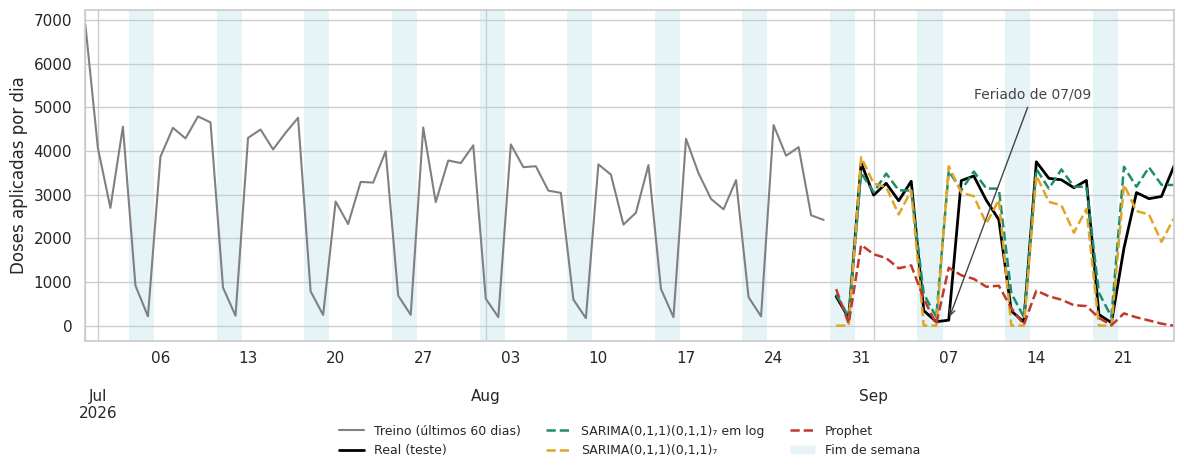

In [24]:
from matplotlib.patches import Patch

tr_s, te_s, prevs = previsoes_corr["TOTAL"]
modelos = ["SARIMA log", "SARIMA(0,1,1)(0,1,1)7", "Prophet"]
cores = {"SARIMA log": "#1E8C6E", "SARIMA(0,1,1)(0,1,1)7": "#E0A526", "Prophet": "#C0392B"}
nomes = {"SARIMA log": "SARIMA(0,1,1)(0,1,1)₇ em log",
         "SARIMA(0,1,1)(0,1,1)7": "SARIMA(0,1,1)(0,1,1)₇",
         "Prophet": "Prophet"}

fig, ax = plt.subplots(figsize=(12, 5))
tr_s.iloc[-60:].plot(ax=ax, color="gray", label="Treino (últimos 60 dias)")
te_s.plot(ax=ax, color="black", lw=2, label="Real (teste)")
for mod in modelos:
    ax.plot(te_s.index, np.clip(prevs[mod], 0, None), "--", lw=1.8,
            color=cores[mod], label=nomes[mod])

idx = tr_s.index[-60:].append(te_s.index)
for d in idx[idx.dayofweek == 5]:
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(days=1, hours=12),
               color="lightblue", alpha=0.3, lw=0)

ax.annotate("Feriado de 07/09", xy=(pd.Timestamp("2026-09-07"), 150),
            xytext=(pd.Timestamp("2026-09-09"), 5200),
            arrowprops=dict(arrowstyle="->", color="#444444"), fontsize=10, color="#444444")

handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="lightblue", alpha=0.3)); labels.append("Fim de semana")
ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.22),
          ncol=3, frameon=False, fontsize=9)
ax.set_xlabel(""); ax.set_ylabel("Doses aplicadas por dia")
salvar("09_total_teste_relatorio"); plt.show()

**Previsão e valores reais da série total no período de teste**

A figura compara, na série total, o valor real do período de teste com três modelos: o SARIMA(0,1,1)(0,1,1)₇ em escala logarítmica, que teve o menor erro (RMSE de 791,3), o mesmo SARIMA sem a transformação logarítmica (RMSE de 873,2) e o Prophet (RMSE de 1.994,4).

Os dois SARIMA acompanham o padrão semanal dos dias úteis. A diferença aparece nos fins de semana: o modelo sem logaritmo representa a queda do fim de semana como um valor fixo, prevê valores negativos e, depois do ajuste para zero, subestima sábados e domingos. Na escala logarítmica, a queda é representada como proporção do nível da série, e as previsões dos fins de semana ficam próximas do valor real.

O Prophet projeta para o período de teste a tendência de queda estimada após as campanhas de influenza e prevê volumes cada vez menores, chegando a quase zero ao fim do período.

O maior erro de todos os modelos ocorre em 07/09, feriado da Independência, para o qual previram volume de dia útil. A segunda-feira seguinte ao feriado estadual de 20/09 também ficou abaixo do previsto.

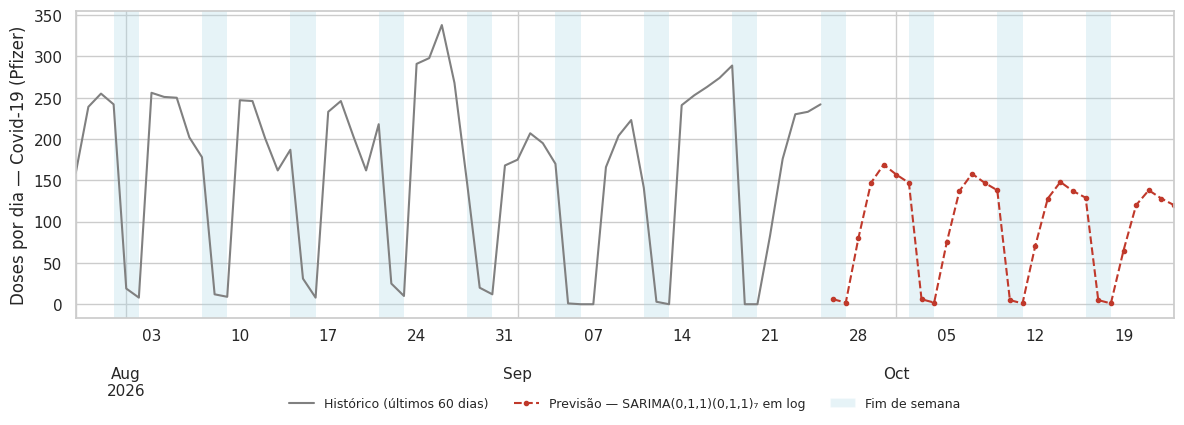

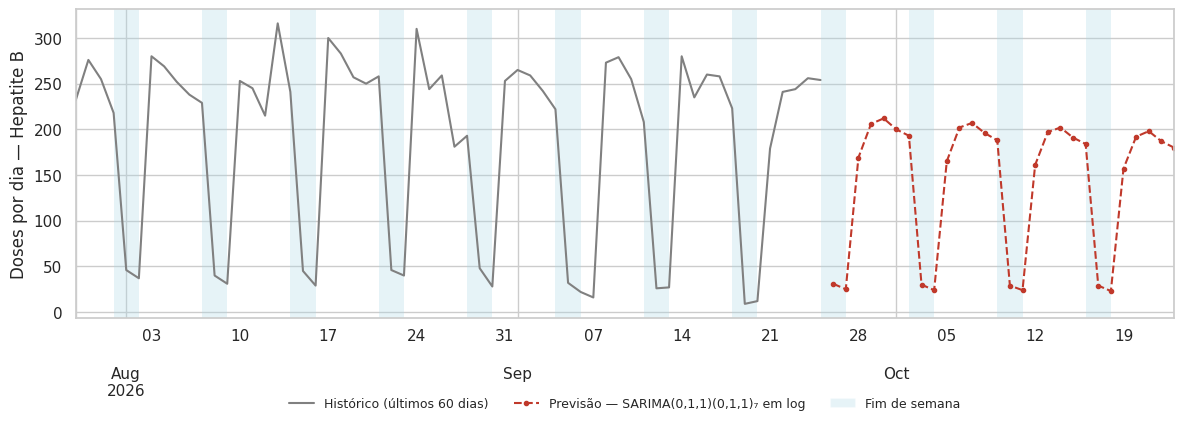

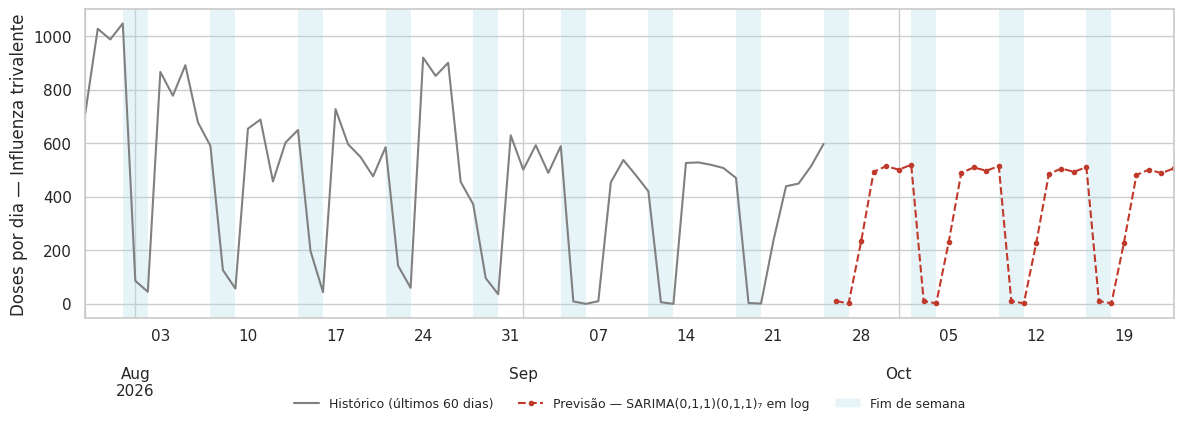

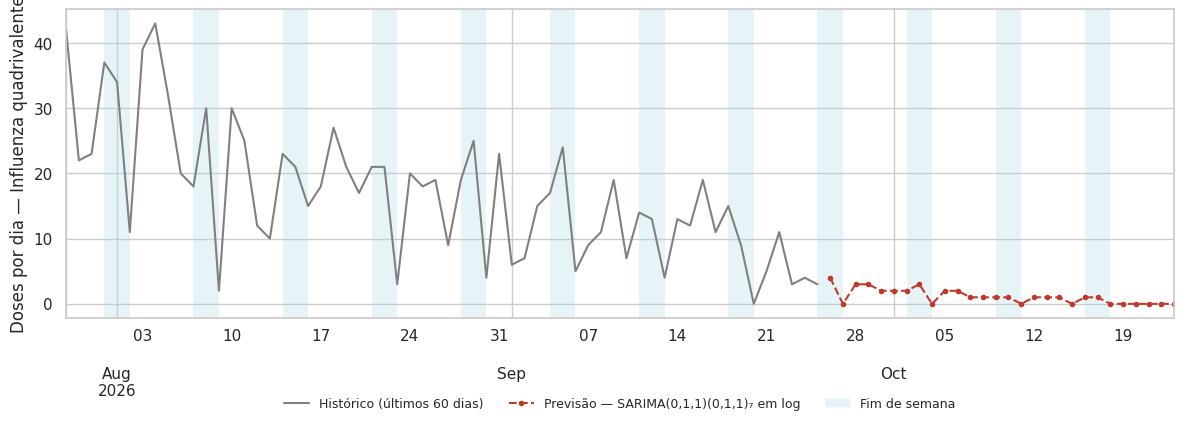

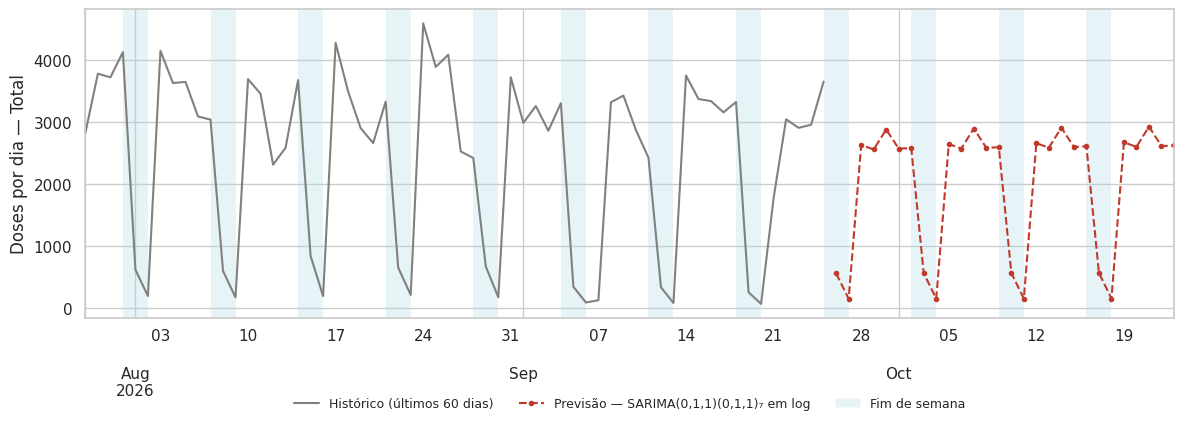

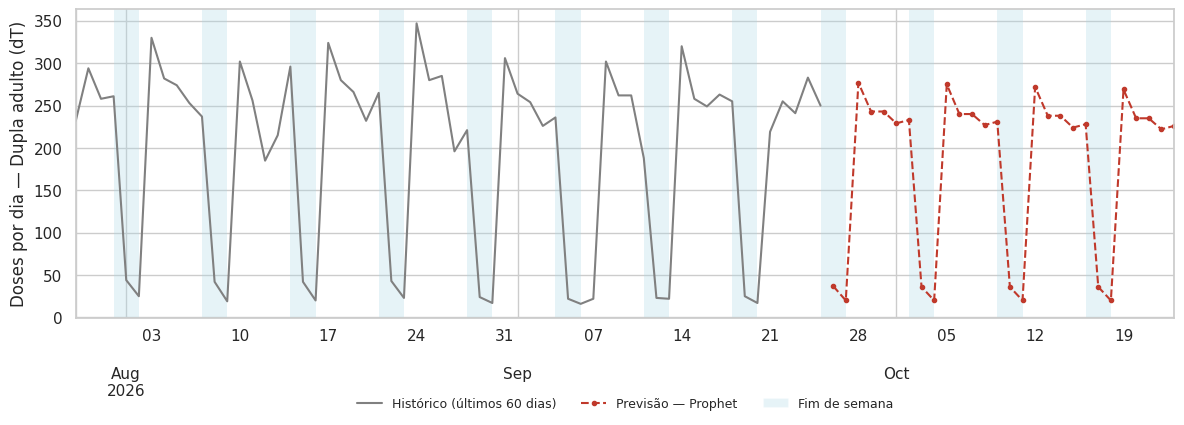

In [26]:
from matplotlib.patches import Patch

nomes_curtos = {"TOTAL": "Total", "INF3": "Influenza trivalente",
                "COV-19 PFIZER-COMIRN": "Covid-19 (Pfizer)", "INF4": "Influenza quadrivalente",
                "dT": "Dupla adulto (dT)", "HB": "Hepatite B"}
nomes_modelos = {"SARIMA log": "SARIMA(0,1,1)(0,1,1)₇ em log", "Prophet": "Prophet",
                 "SARIMA(0,1,1)(0,1,1)7": "SARIMA(0,1,1)(0,1,1)₇",
                 "SARIMA (busca)": "SARIMA (busca em grade)",
                 "Sazonal ingênuo (7d)": "Sazonal ingênuo (7 dias)",
                 "Média dia-semana 4sem": "Média por dia da semana (4 semanas)", "Naive": "Ingênuo"}
modelo_usado = melhor_corr.set_index("serie")["modelo"]

for nome in df_futuro.columns:
    s = series_corr[nome]
    fig, ax = plt.subplots(figsize=(12, 4.5))
    s.iloc[-60:].plot(ax=ax, color="gray", label="Histórico (últimos 60 dias)")
    df_futuro[nome].plot(ax=ax, color="#C0392B", ls="--", marker="o", ms=3,
                         label=f"Previsão — {nomes_modelos[modelo_usado[nome]]}")

    idx_all = s.index[-60:].append(df_futuro.index)
    for d in idx_all[idx_all.dayofweek == 5]:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(days=1, hours=12),
                   color="lightblue", alpha=0.3, lw=0)

    handles, labels = ax.get_legend_handles_labels()
    handles.append(Patch(facecolor="lightblue", alpha=0.3)); labels.append("Fim de semana")
    ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.22),
              ncol=3, frameon=False, fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel(f"Doses por dia — {nomes_curtos[nome]}")
    salvar(f"11_futuro_{nome[:30].replace(' ', '_')}")
    plt.show(); plt.close(fig)

**Previsão futura**

Foram previstos os 28 dias seguintes ao fim da base (26/09 a 23/10/2026). Cada série usou o modelo com menor RMSE no teste, reajustado com todo o histórico: o SARIMA log no TOTAL, na INF3, na COV-19, na INF4 e na HB, e o Prophet na dT.

A Tabela Y resume as previsões das duas primeiras semanas em relação à última semana observada (19 a 25/09). A dT (−0,6%) e a INF3 (+1,4%) mantêm o volume recente, e o TOTAL tem queda leve (−5,0%). A HB (−13,3%) e a COV-19 (−26,6%) têm quedas maiores, que não correspondem a tendências observadas nos dados: a HB é uma série estável há meses, e a COV-19 vinha em alta nas últimas semanas. No período de teste, o SARIMA log não subestimou essas séries, e seu erro médio foi positivo (+9 doses por dia na HB e +20 na COV-19). Uma explicação provável é a presença de dias com volume atipicamente baixo na última semana da série (o fim de semana de 19 e 20/09, que incluiu o feriado estadual da Revolução Farroupilha, e a segunda-feira, 21/09), aos quais o modelo em escala logarítmica é sensível. Essas quedas devem ser interpretadas como incerteza da previsão. Na INF4, a previsão segue a queda que a série apresenta desde julho, com valores entre 0 e 4 doses por dia.

Todas as previsões mantêm a sazonalidade semanal, com quedas aos sábados e domingos, sem valores negativos. O período previsto inclui o feriado de 12/10 (Nossa Senhora Aparecida), que o SARIMA não incorpora. Os valores previstos podem ser comparados com os dados reais quando a base for atualizada.

## Interpretação e limitações

**Sazonalidade semanal.** Em todas as séries, a sazonalidade semanal é o padrão dominante, com quedas acentuadas aos sábados e domingos. A amplitude dessa queda é proporcional ao nível da série, o que explica o melhor desempenho do SARIMA em escala logarítmica, que representa a sazonalidade como proporção e não gera previsões negativas nos fins de semana.

**Modelos simples generalizaram melhor.** A busca em grade do SARIMA não superou a especificação fixa (0,1,1)(0,1,1)₇, indicada pela análise de autocorrelação, em nenhuma série de forma relevante. Com séries curtas e com eventos de campanha, termos adicionais melhoraram o ajuste no treino sem melhorar a previsão.

**Prophet.** O Prophet teve bom desempenho nas séries de rotina (hepatite B e dT), mas foi o pior modelo nas séries afetadas por campanhas (total, influenza trivalente e covid). Nelas, a tendência estimada projetou a queda posterior às campanhas e levou as previsões a valores próximos de zero.

**Campanhas e eventos pontuais.** A série tem menos de um ano, e as campanhas de influenza aparecem uma única vez, o que impede os modelos de aprender sua repetição anual. O Dia D da Multivacinação (22/08), no último sábado do treino, foi substituído pela mediana dos quatro sábados anteriores, porque distorcia os modelos que usam a semana mais recente. O Dia D de 11/04 foi mantido, por ocorrer durante a campanha de influenza, quando o nível da série estava elevado.

**Feriados.** O SARIMA não incorpora feriados. O maior erro de todos os modelos no teste ocorreu em 07/09, feriado da Independência, e o período previsto inclui o feriado de 12/10, para o qual as previsões indicam volume de dia útil.

**Validação.** Os modelos foram avaliados em uma única janela de teste, de 28 dias. A ordem entre eles é sensível ao período escolhido, e várias diferenças de RMSE foram pequenas. O SARIMA em escala logarítmica foi incluído na comparação depois da primeira rodada, motivado pelas previsões negativas dos modelos aditivos.

**Dados.** A base foi extraída do Portal de Dados Abertos do SUS em 02/10/2026. Como o Ministério da Saúde atualiza os arquivos semanalmente, com a inclusão de registros digitados com atraso, os valores podem diferir de versões posteriores, sobretudo nas últimas semanas da série. O último dia da base (26/09) foi removido por estar incompleto. A série representa a vacinação dos moradores de Porto Alegre, em qualquer local de aplicação, e não a demanda das unidades de saúde do município.

**Incerteza das previsões.** As quedas previstas para hepatite B (−13,3%) e covid (−26,6%) não correspondem a tendências observadas nos dados e devem ser interpretadas como incerteza da previsão. Os valores previstos podem ser comparados com os dados reais quando a base de outubro for publicada.

**Possíveis melhorias:** incluir variáveis indicadoras de campanhas e feriados nos modelos, avaliar os modelos em várias janelas de teste sucessivas e acumular mais de um ano de dados, para capturar a repetição das campanhas.